In [1]:
# =========================
# CELL 1: SETUP + CONFIG
# =========================
import os, json, time, itertools, random
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

# from google.colab import drive
# drive.mount('/content/drive')

print("GPU Available:", tf.config.list_physical_devices('GPU'))
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')

SEED = 42
tf.random.set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

IMG_SIZE = (224, 224)
VAL_SPLIT = 0.15  # carved from TRAINING data only; test set never touched during training

OPTIMIZERS = ["adam", "rmsprop", "sgd", "adamw"]  # AdamW added (used in the original ConvNeXt paper)
LEARNING_RATES = [1e-3, 1e-4, 1e-5]
BATCH_SIZES = [10, 16, 32]
COMBINATIONS = list(itertools.product(OPTIMIZERS, LEARNING_RATES, BATCH_SIZES))
print("Total DeepFire/Forest hyperparameter configurations:", len(COMBINATIONS))


GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Total DeepFire/Forest hyperparameter configurations: 36


In [2]:
# =========================
# CELL 2: ORGANIZED FOLDER STRUCTURE (all on Google Drive)
# =========================
BASE_DIR = "/content/drive/MyDrive/CONVNEXT_FIRE_V3"

CKPT_DIR       = os.path.join(BASE_DIR, "checkpoints")
CKPT_DEEPFIRE  = os.path.join(CKPT_DIR, "deepfire")
CKPT_FOREST    = os.path.join(CKPT_DIR, "forest")
CKPT_BASELINES = os.path.join(CKPT_DIR, "baselines")
CKPT_FEWSHOT   = os.path.join(CKPT_DIR, "fewshot")

RESULTS_DIR = os.path.join(BASE_DIR, "results")
FIGURES_DIR = os.path.join(BASE_DIR, "figures")
TFLITE_DIR  = os.path.join(BASE_DIR, "tflite")

for d in [CKPT_DEEPFIRE, CKPT_FOREST, CKPT_BASELINES, CKPT_FEWSHOT,
          RESULTS_DIR, FIGURES_DIR, TFLITE_DIR]:
    os.makedirs(d, exist_ok=True)

print("Folder structure:")
print(f"  {BASE_DIR}/")
print(f"    checkpoints/deepfire/    <- one subfolder per DeepFire hyperparameter run")
print(f"    checkpoints/forest/      <- one subfolder per Forest hyperparameter run")
print(f"    checkpoints/baselines/   <- one subfolder per baseline-model x dataset run")
print(f"    checkpoints/fewshot/     <- one subfolder per few-shot k-value run")
print(f"    results/                 <- every stage's results as its own .json file")
print(f"    figures/                 <- every generated plot (.png)")
print(f"    tflite/                  <- quantized deployment models")

# ---- Generic checkpoint helpers used by every resumable stage below ----
def save_checkpoint(stage_name, data):
    path = os.path.join(RESULTS_DIR, f"{stage_name}.json")
    with open(path, "w") as f:
        json.dump(data, f, indent=2)

def load_checkpoint(stage_name, default=None):
    path = os.path.join(RESULTS_DIR, f"{stage_name}.json")
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    return default if default is not None else {}


Folder structure:
  /content/drive/MyDrive/CONVNEXT_FIRE_V3/
    checkpoints/deepfire/    <- one subfolder per DeepFire hyperparameter run
    checkpoints/forest/      <- one subfolder per Forest hyperparameter run
    checkpoints/baselines/   <- one subfolder per baseline-model x dataset run
    checkpoints/fewshot/     <- one subfolder per few-shot k-value run
    results/                 <- every stage's results as its own .json file
    figures/                 <- every generated plot (.png)
    tflite/                  <- quantized deployment models



===== DEEPFIRE TRAIN =====
📂 /content/drive/MyDrive/AIML/Data/Deepfire_dataset/Training
Found 1520 files across 2 classes: {'fire': 760, 'nofire': 760}

===== DEEPFIRE TEST =====
📂 /content/drive/MyDrive/AIML/Data/Deepfire_dataset/Testing
Found 380 files across 2 classes: {'fire': 190, 'nofire': 190}

===== FOREST TRAIN =====
📂 /content/drive/MyDrive/AIML/Data/Forest_fire_images_dataset/Train_Data
Found 4611 files across 2 classes: {'Fire': 2111, 'Non_Fire': 2500}

===== FOREST TEST =====
📂 /content/drive/MyDrive/AIML/Data/Forest_fire_images_dataset/Test_Data
Found 50 files across 2 classes: {'Fire': 25, 'Non_Fire': 25}

🔍 Integrity check: DeepFire Train
  fire        : total=  760  zero-byte=  0  corrupt=  0  usable=  760
  nofire      : total=  760  zero-byte=  0  corrupt=  0  usable=  760

🔍 Integrity check: Forest Train
  Fire        : total= 2111  zero-byte=  0  corrupt=  0  usable= 2111
  Non_Fire    : total= 2500  zero-byte=  0  corrupt=  0  usable= 2500


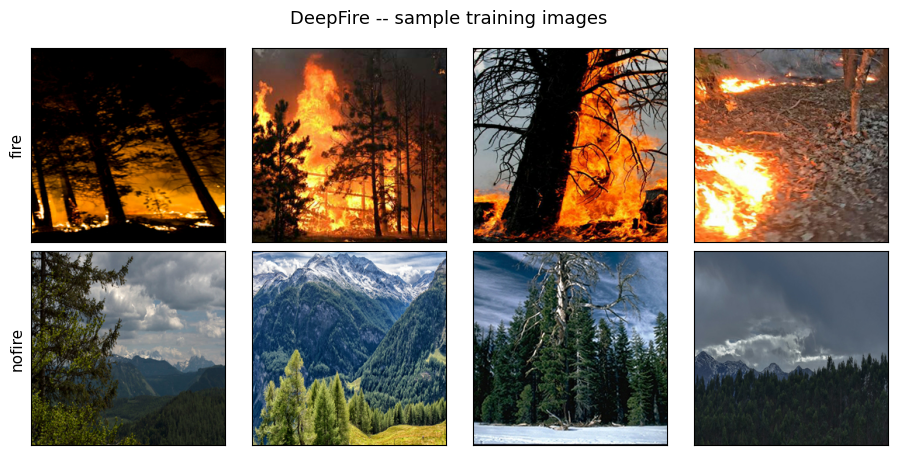

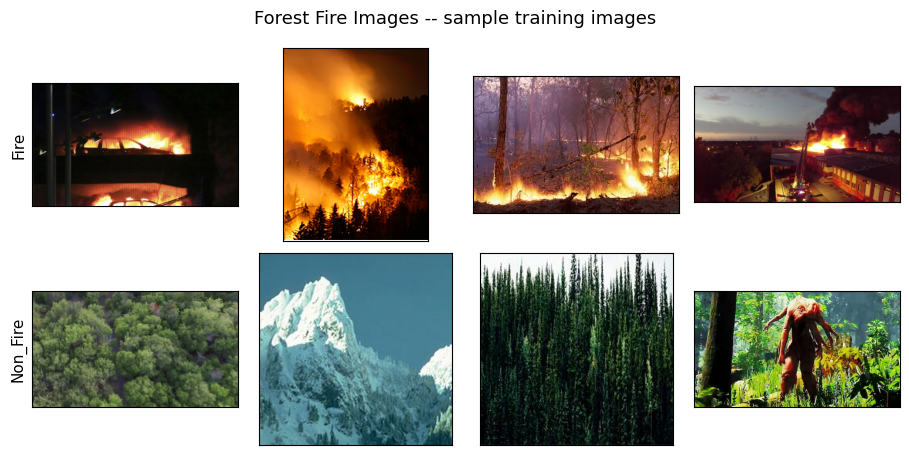

In [3]:
# =========================
# CELL 3: DATASET PATHS, INTEGRITY CHECK, AND SAMPLE IMAGE DISPLAY
# =========================
import matplotlib.pyplot as plt

DEEPFIRE_TRAIN = "/content/drive/MyDrive/AIML/Data/Deepfire_dataset/Training"
DEEPFIRE_TEST  = "/content/drive/MyDrive/AIML/Data/Deepfire_dataset/Testing"
FOREST_TRAIN   = "/content/drive/MyDrive/AIML/Data/Forest_fire_images_dataset/Train_Data"
FOREST_TEST    = "/content/drive/MyDrive/AIML/Data/Forest_fire_images_dataset/Test_Data"


def show_dataset_info(name, path):
    print(f"\n===== {name.upper()} =====")
    print(f"📂 {path}")
    if not os.path.exists(path):
        print("❌ Path not found!")
        return
    class_names = sorted([d for d in os.listdir(path) if os.path.isdir(os.path.join(path, d))])
    counts, total = {}, 0
    for cls in class_names:
        n = len([f for f in os.listdir(os.path.join(path, cls)) if os.path.isfile(os.path.join(path, cls, f))])
        counts[cls] = n
        total += n
    print(f"Found {total} files across {len(class_names)} classes: {counts}")


def check_dataset_integrity(name, path):
    """Scans for zero-byte and undecodable (corrupt) image files per class."""
    print(f"\n🔍 Integrity check: {name}")
    class_names = sorted([d for d in os.listdir(path) if os.path.isdir(os.path.join(path, d))])
    report = {}
    for cls in class_names:
        cls_dir = os.path.join(path, cls)
        n_total = n_zero = n_corrupt = 0
        for fname in os.listdir(cls_dir):
            fpath = os.path.join(cls_dir, fname)
            if not os.path.isfile(fpath):
                continue
            n_total += 1
            if os.path.getsize(fpath) == 0:
                n_zero += 1
                continue
            try:
                _ = tf.io.decode_image(tf.io.read_file(fpath), channels=3, expand_animations=False)
            except Exception:
                n_corrupt += 1
        report[cls] = {"total": n_total, "zero_byte": n_zero, "corrupt": n_corrupt, "usable": n_total - n_zero - n_corrupt}
        print(f"  {cls:12s}: total={n_total:5d}  zero-byte={n_zero:3d}  corrupt={n_corrupt:3d}  usable={n_total - n_zero - n_corrupt:5d}")
    return report


def display_sample_grid(dataset_path, title, n_per_class=4, save_name=None):
    class_names = sorted([d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d))])
    fig, axes = plt.subplots(len(class_names), n_per_class, figsize=(n_per_class * 2.3, len(class_names) * 2.3))
    if len(class_names) == 1:
        axes = np.expand_dims(axes, 0)
    for row, cls in enumerate(class_names):
        cls_dir = os.path.join(dataset_path, cls)
        files = [f for f in os.listdir(cls_dir) if os.path.isfile(os.path.join(cls_dir, f)) and os.path.getsize(os.path.join(cls_dir, f)) > 0]
        chosen = random.sample(files, min(n_per_class, len(files)))
        for col in range(n_per_class):
            ax = axes[row, col]
            if col < len(chosen):
                try:
                    img = tf.io.decode_image(tf.io.read_file(os.path.join(cls_dir, chosen[col])), channels=3, expand_animations=False)
                    ax.imshow(img.numpy())
                except Exception:
                    ax.text(0.5, 0.5, "decode error", ha='center', va='center')
            ax.set_xticks([]); ax.set_yticks([])
            if col == 0:
                ax.set_ylabel(cls, fontsize=11)
    plt.suptitle(title, fontsize=13)
    plt.tight_layout()
    if save_name:
        plt.savefig(os.path.join(FIGURES_DIR, save_name), dpi=150, bbox_inches='tight')
    plt.show()


show_dataset_info("DeepFire Train", DEEPFIRE_TRAIN)
show_dataset_info("DeepFire Test", DEEPFIRE_TEST)
show_dataset_info("Forest Train", FOREST_TRAIN)
show_dataset_info("Forest Test", FOREST_TEST)

deepfire_integrity = check_dataset_integrity("DeepFire Train", DEEPFIRE_TRAIN)
forest_integrity = check_dataset_integrity("Forest Train", FOREST_TRAIN)
save_checkpoint("dataset_integrity", {"deepfire": deepfire_integrity, "forest": forest_integrity})

display_sample_grid(DEEPFIRE_TRAIN, "DeepFire -- sample training images", save_name="samples_deepfire.png")
display_sample_grid(FOREST_TRAIN, "Forest Fire Images -- sample training images", save_name="samples_forest.png")


Original training images: 1520
If USE_AUGMENTATION=True with multiplier=3x:
  -> 4560 augmented image VIEWS seen per epoch (generated on-the-fly, not saved as separate files)

Demonstration of augmentation pipeline on one sample image (illustrative only -- USE_AUGMENTATION is currently False ):


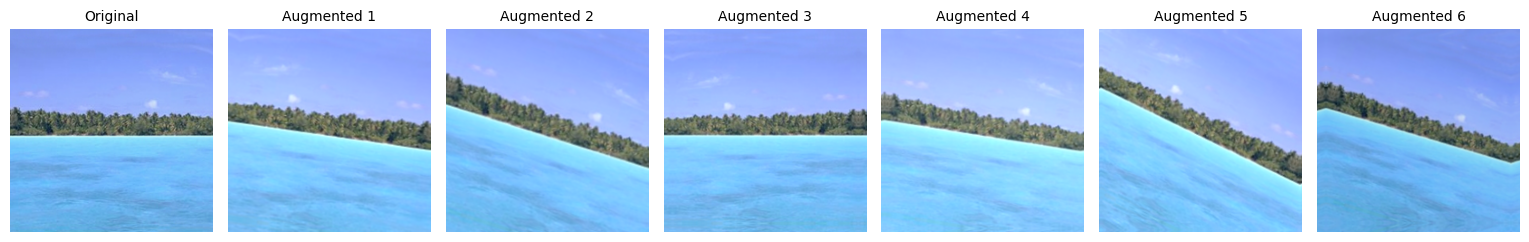

In [4]:
# =========================
# CELL 4: DATA AUGMENTATION (OFF by default -- see note below)
# =========================
# The reference study this work builds on (Khirani et al., 2026) and the DeepFire /
# Forest Fire Images benchmarks it compares against explicitly use NO augmentation
# ("kept same as original studies") to keep results directly comparable. USE_AUGMENTATION
# therefore defaults to False. The pipeline below is fully implemented and toggleable --
# set USE_AUGMENTATION = True if you want to report an augmented variant as an additional
# ablation, but the primary reported numbers in this study use the unaugmented pipeline.

USE_AUGMENTATION = False
AUGMENTATION_MULTIPLIER = 3  # if enabled: each image is seen this many times per epoch,
                              # each time with a different random augmentation (generated
                              # on-the-fly in memory -- NOT pre-materialized as extra files
                              # on disk, which is standard practice and avoids inflating
                              # storage/duplicating the dataset)

augmentation_layer = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.15),
    layers.RandomContrast(0.1),
], name="augmentation")


def count_augmented_images(train_dir, multiplier=AUGMENTATION_MULTIPLIER):
    class_names = [d for d in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, d))]
    n_original = sum(len(os.listdir(os.path.join(train_dir, c))) for c in class_names)
    n_effective = n_original * multiplier
    print(f"Original training images: {n_original}")
    print(f"If USE_AUGMENTATION=True with multiplier={multiplier}x:")
    print(f"  -> {n_effective} augmented image VIEWS seen per epoch (generated on-the-fly, not saved as separate files)")
    return n_original, n_effective


def display_augmentation_samples(image_path, n_samples=6, save_name=None):
    img = tf.io.decode_image(tf.io.read_file(image_path), channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img_batch = tf.expand_dims(img, 0)

    fig, axes = plt.subplots(1, n_samples + 1, figsize=((n_samples + 1) * 2.2, 2.6))
    axes[0].imshow(tf.cast(img, tf.uint8).numpy()); axes[0].set_title("Original", fontsize=10); axes[0].axis('off')
    for i in range(n_samples):
        aug_img = augmentation_layer(img_batch, training=True)[0]
        aug_img = tf.clip_by_value(aug_img, 0, 255)
        axes[i + 1].imshow(tf.cast(aug_img, tf.uint8).numpy())
        axes[i + 1].set_title(f"Augmented {i + 1}", fontsize=10)
        axes[i + 1].axis('off')
    plt.tight_layout()
    if save_name:
        plt.savefig(os.path.join(FIGURES_DIR, save_name), dpi=150, bbox_inches='tight')
    plt.show()


n_orig, n_eff = count_augmented_images(DEEPFIRE_TRAIN)

# Demonstration: show what augmentation WOULD look like, even though it's off by default.
sample_class_dir = os.path.join(DEEPFIRE_TRAIN, os.listdir(DEEPFIRE_TRAIN)[0])
sample_image = os.path.join(sample_class_dir, os.listdir(sample_class_dir)[0])
print("\nDemonstration of augmentation pipeline on one sample image (illustrative only -- USE_AUGMENTATION is currently", USE_AUGMENTATION, "):")
display_augmentation_samples(sample_image, save_name="augmentation_demo.png")


In [5]:
# =========================
# CELL 5: DATA LOADING (leak-free train/val/test split, optional augmentation)
# =========================
def load_dataset(path, batch_size=32, shuffle=True):
    return tf.keras.preprocessing.image_dataset_from_directory(
        path, image_size=IMG_SIZE, batch_size=batch_size, label_mode="binary", shuffle=shuffle
    )


def load_train_val_test(train_path, test_path, batch, use_augmentation=USE_AUGMENTATION):
    """
    Leak-free split: validation is carved from the TRAINING directory only (never from
    the test directory). The test set is loaded separately and is not touched by
    checkpointing, early stopping, or hyperparameter selection -- only for the final,
    one-time evaluation after model/config selection is complete.
    """
    train_ds = tf.keras.preprocessing.image_dataset_from_directory(
        train_path, image_size=IMG_SIZE, batch_size=batch, label_mode="binary",
        validation_split=VAL_SPLIT, subset="training", seed=SEED
    )
    val_ds = tf.keras.preprocessing.image_dataset_from_directory(
        train_path, image_size=IMG_SIZE, batch_size=batch, label_mode="binary",
        validation_split=VAL_SPLIT, subset="validation", seed=SEED
    )
    test_ds = tf.keras.preprocessing.image_dataset_from_directory(
        test_path, image_size=IMG_SIZE, batch_size=batch, label_mode="binary", shuffle=False
    )

    AUTOTUNE = tf.data.AUTOTUNE
    if use_augmentation:
        train_ds = train_ds.map(lambda x, y: (augmentation_layer(x, training=True), y), num_parallel_calls=AUTOTUNE)

    train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
    val_ds   = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
    test_ds  = test_ds.cache().prefetch(buffer_size=AUTOTUNE)
    return train_ds, val_ds, test_ds


In [6]:
# =========================
# CELL 6: MODEL BUILDERS -- proposed model + baseline models
# =========================
# Which baselines are actually trained IN THIS CODE, and which are literature-cited:
#
#   Trained here (available in tf.keras.applications, identical leak-free pipeline):
#     - MobileNetV2
#     - EfficientNetB0
#     - ResNet50   (ResNet-18 itself is NOT shipped in tf.keras.applications; ResNet50
#                    is used as the closest available "ResNet family" member)
#
#   NOT trained here, remain literature-cited (Khirani et al., 2026) in Tables 4/5 and
#   Fig. 10, clearly labeled as such wherever they are reported:
#     - AlexNet, GoogLeNet (Inception-v1), SqueezeNet, ResNet-18
#     These architectures were never shipped in tf.keras.applications -- they originate
#     from Caffe/PyTorch model zoos. Reproducing them exactly would require either a
#     from-scratch reimplementation (introducing its own risk of not matching the
#     original paper's exact training behaviour) or switching frameworks entirely. We
#     report them as-cited rather than risk an unfaithful reimplementation.

def build_model(lr, optimizer_name):
    """Proposed model: ConvNeXt-Tiny."""
    base_model = tf.keras.applications.ConvNeXtTiny(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
    return _attach_head(base_model, lr, optimizer_name)


def build_baseline_model(backbone_name, lr, optimizer_name):
    if backbone_name == "MobileNetV2":
        base = tf.keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
    elif backbone_name == "EfficientNetB0":
        base = tf.keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
    elif backbone_name == "ResNet50":
        base = tf.keras.applications.ResNet50(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
    else:
        raise ValueError(f"Unknown baseline: {backbone_name}")
    return _attach_head(base, lr, optimizer_name)


def _attach_head(base_model, lr, optimizer_name):
    for layer in base_model.layers[:-20]:
        layer.trainable = False

    x = base_model.output
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    output = layers.Dense(1, activation='sigmoid', dtype='float32')(x)
    model = tf.keras.Model(inputs=base_model.input, outputs=output)

    if optimizer_name == "adam":
        opt = tf.keras.optimizers.Adam(learning_rate=lr)
    elif optimizer_name == "rmsprop":
        opt = tf.keras.optimizers.RMSprop(learning_rate=lr)
    elif optimizer_name == "adamw":
        opt = tf.keras.optimizers.AdamW(learning_rate=lr, weight_decay=0.05)
    else:
        opt = tf.keras.optimizers.SGD(learning_rate=lr, momentum=0.9)

    model.compile(optimizer=opt, loss="binary_crossentropy", metrics=["accuracy"])
    return model


BASELINE_NAMES = ["MobileNetV2", "EfficientNetB0", "ResNet50"]
model = build_model(1e-4, "adam")
model.summary()


111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_pres… │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stem  │ (None, 56, 56,    │      4,896 │ convnext_tiny_pr… │
│ (Sequential)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │      4,800 │ convnext_tiny_st… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │        192 │ convnext_tiny_st… │
│ (LayerNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │     37,248 │ convnext_tiny_st… │
│ (Dense)             │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │          0 │ convnext_tiny_st… │
│ (Activation)        │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │     36,960 │ convnext_tiny_st… │
│ (Dense)             │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │         96 │ convnext_tiny_st… │
│ (LayerScale)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │          0 │ convnext_tiny_st… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 56, 56,    │          0 │ convnext_tiny_st… │
│                     │ 96)               │            │ convnext_tiny_st… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │      4,800 │ add[0][0]         │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │        192 │ convnext_tiny_st… │
│ (LayerNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │     37,248 │ convnext_tiny_st… │
│ (Dense)             │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │          0 │ convnext_tiny_st… │
│ (Activation)        │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │     36,960 │ convnext_tiny_st… │
│ (Dense)             │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │         96 │ convnext_tiny_st

 Total params: 28,020,321 (106.89 MB)

 Trainable params: 14,449,665 (55.12 MB)

 Non-trainable params: 13,570,656 (51.77 MB)

In [7]:
# =========================
# CELL 7: DEEPFIRE TRAINING (RESUMABLE: skips any run_name already in the checkpoint)
# =========================
results = load_checkpoint("deepfire_results", default={})
EPOCHS = 20

for opt, lr, batch in COMBINATIONS:
    run_name = f"{opt}_lr{lr}_bs{batch}"
    run_dir = os.path.join(CKPT_DEEPFIRE, run_name)
    os.makedirs(run_dir, exist_ok=True)

    if run_name in results:
        print(f"⏭  {run_name}: already completed, skipping")
        continue

    print(f"\n▶  Running: {run_name}")
    checkpoint_path = os.path.join(run_dir, "best_model.h5")

    try:
        train_ds, val_ds, test_ds = load_train_val_test(DEEPFIRE_TRAIN, DEEPFIRE_TEST, batch)
        model = build_model(lr, opt)

        checkpoint = ModelCheckpoint(checkpoint_path, monitor='val_accuracy', save_best_only=True, verbose=0)
        early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

        start_time = time.time()
        history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                             callbacks=[checkpoint, early_stop], verbose=1)
        duration = time.time() - start_time

        best_val_acc = max(history.history["val_accuracy"])
        with open(os.path.join(run_dir, "history.json"), "w") as f:
            json.dump(history.history, f)

        model.load_weights(checkpoint_path)
        _, test_acc = model.evaluate(test_ds, verbose=0)

        results[run_name] = {"val_accuracy": float(best_val_acc), "test_accuracy": float(test_acc),
                              "time_sec": duration, "model_path": checkpoint_path}
        save_checkpoint("deepfire_results", results)  # <-- saved immediately, not just at the end
        print(f"✅ {run_name}: val_acc={best_val_acc:.4f}, test_acc={test_acc:.4f}  (checkpoint saved)")

    except Exception as e:
        print(f"❌ {run_name} failed: {e}")
        continue

print(f"\n{len(results)}/{len(COMBINATIONS)} DeepFire configurations complete.")


⏭  adam_lr0.001_bs10: already completed, skipping
⏭  adam_lr0.001_bs16: already completed, skipping
⏭  adam_lr0.001_bs32: already completed, skipping
⏭  adam_lr0.0001_bs10: already completed, skipping
⏭  adam_lr0.0001_bs16: already completed, skipping
⏭  adam_lr0.0001_bs32: already completed, skipping
⏭  adam_lr1e-05_bs10: already completed, skipping
⏭  adam_lr1e-05_bs16: already completed, skipping
⏭  adam_lr1e-05_bs32: already completed, skipping
⏭  rmsprop_lr0.001_bs10: already completed, skipping
⏭  rmsprop_lr0.001_bs16: already completed, skipping
⏭  rmsprop_lr0.001_bs32: already completed, skipping
⏭  rmsprop_lr0.0001_bs10: already completed, skipping
⏭  rmsprop_lr0.0001_bs16: already completed, skipping
⏭  rmsprop_lr0.0001_bs32: already completed, skipping
⏭  rmsprop_lr1e-05_bs10: already completed, skipping
⏭  rmsprop_lr1e-05_bs16: already completed, skipping
⏭  rmsprop_lr1e-05_bs32: already completed, skipping
⏭  sgd_lr0.001_bs10: already completed, skipping
⏭  sgd_lr0.001_bs1

In [8]:
# =========================
# CELL 8: FOREST FIRE TRAINING (RESUMABLE)
# =========================
forest_results = load_checkpoint("forest_results", default={})
EPOCHS = 20

for opt, lr, batch in COMBINATIONS:
    run_name = f"{opt}_lr{lr}_bs{batch}"
    run_dir = os.path.join(CKPT_FOREST, run_name)
    os.makedirs(run_dir, exist_ok=True)

    if run_name in forest_results:
        print(f"⏭  {run_name}: already completed, skipping")
        continue

    print(f"\n🌲 Running: {run_name}")
    checkpoint_path = os.path.join(run_dir, "best_model.h5")

    try:
        train_ds, val_ds, test_ds = load_train_val_test(FOREST_TRAIN, FOREST_TEST, batch)
        model = build_model(lr, opt)

        checkpoint = ModelCheckpoint(checkpoint_path, monitor='val_accuracy', save_best_only=True, verbose=0)
        early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

        history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                             callbacks=[checkpoint, early_stop], verbose=1)

        best_val_acc = max(history.history["val_accuracy"])
        with open(os.path.join(run_dir, "history.json"), "w") as f:
            json.dump(history.history, f)

        model.load_weights(checkpoint_path)
        _, test_acc = model.evaluate(test_ds, verbose=0)

        forest_results[run_name] = {"val_accuracy": float(best_val_acc), "test_accuracy": float(test_acc),
                                     "model_path": checkpoint_path}
        save_checkpoint("forest_results", forest_results)
        print(f"✅ {run_name}: val_acc={best_val_acc:.4f}, test_acc={test_acc:.4f}  (checkpoint saved)")

    except Exception as e:
        print(f"❌ {run_name} failed: {e}")
        continue

print(f"\n{len(forest_results)}/{len(COMBINATIONS)} Forest configurations complete.")


⏭  adam_lr0.001_bs10: already completed, skipping
⏭  adam_lr0.001_bs16: already completed, skipping
⏭  adam_lr0.001_bs32: already completed, skipping
⏭  adam_lr0.0001_bs10: already completed, skipping
⏭  adam_lr0.0001_bs16: already completed, skipping
⏭  adam_lr0.0001_bs32: already completed, skipping
⏭  adam_lr1e-05_bs10: already completed, skipping
⏭  adam_lr1e-05_bs16: already completed, skipping
⏭  adam_lr1e-05_bs32: already completed, skipping
⏭  rmsprop_lr0.001_bs10: already completed, skipping
⏭  rmsprop_lr0.001_bs16: already completed, skipping
⏭  rmsprop_lr0.001_bs32: already completed, skipping
⏭  rmsprop_lr0.0001_bs10: already completed, skipping
⏭  rmsprop_lr0.0001_bs16: already completed, skipping
⏭  rmsprop_lr0.0001_bs32: already completed, skipping
⏭  rmsprop_lr1e-05_bs10: already completed, skipping
⏭  rmsprop_lr1e-05_bs16: already completed, skipping
⏭  rmsprop_lr1e-05_bs32: already completed, skipping
⏭  sgd_lr0.001_bs10: already completed, skipping
⏭  sgd_lr0.001_bs1

In [9]:
# =========================
# CELL 9: BASELINE MODELS TRAINING (RESUMABLE)
# For each of MobileNetV2 / EfficientNetB0 / ResNet50, trains ONE well-tuned
# configuration (Adam, lr=1e-4, batch=16) on EACH dataset -- not a full 27-point grid,
# for compute-cost reasons. This is disclosed explicitly: the goal here is a fair,
# code-verified, apples-to-apples comparison for the calibration/ECE ablation table
# (Cell 25), which needs actual trained models -- not a hyperparameter search.
# =========================
baseline_results = load_checkpoint("baseline_results", default={})
BASELINE_CONFIG = {"opt": "adam", "lr": 1e-4, "batch": 16}
EPOCHS = 20

baseline_jobs = [(name, "deepfire", DEEPFIRE_TRAIN, DEEPFIRE_TEST) for name in BASELINE_NAMES] + \
                [(name, "forest", FOREST_TRAIN, FOREST_TEST) for name in BASELINE_NAMES]

for backbone_name, dataset_key, train_path, test_path in baseline_jobs:
    run_key = f"{backbone_name}_{dataset_key}"
    run_dir = os.path.join(CKPT_BASELINES, run_key)
    os.makedirs(run_dir, exist_ok=True)

    if run_key in baseline_results:
        print(f"⏭  {run_key}: already completed, skipping")
        continue

    print(f"\n▶  Training baseline: {run_key}")
    checkpoint_path = os.path.join(run_dir, "best_model.h5")

    try:
        train_ds, val_ds, test_ds = load_train_val_test(train_path, test_path, BASELINE_CONFIG["batch"])
        model = build_baseline_model(backbone_name, BASELINE_CONFIG["lr"], BASELINE_CONFIG["opt"])

        checkpoint = ModelCheckpoint(checkpoint_path, monitor='val_accuracy', save_best_only=True, verbose=0)
        early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

        history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                             callbacks=[checkpoint, early_stop], verbose=1)

        best_val_acc = max(history.history["val_accuracy"])
        model.load_weights(checkpoint_path)
        _, test_acc = model.evaluate(test_ds, verbose=0)

        baseline_results[run_key] = {"backbone": backbone_name, "dataset": dataset_key,
                                      "val_accuracy": float(best_val_acc), "test_accuracy": float(test_acc),
                                      "model_path": checkpoint_path}
        save_checkpoint("baseline_results", baseline_results)
        print(f"✅ {run_key}: val_acc={best_val_acc:.4f}, test_acc={test_acc:.4f}  (checkpoint saved)")

    except Exception as e:
        print(f"❌ {run_key} failed: {e}")
        continue

print(f"\n{len(baseline_results)}/{len(baseline_jobs)} baseline runs complete.")


⏭  MobileNetV2_deepfire: already completed, skipping
⏭  EfficientNetB0_deepfire: already completed, skipping
⏭  ResNet50_deepfire: already completed, skipping
⏭  MobileNetV2_forest: already completed, skipping
⏭  EfficientNetB0_forest: already completed, skipping
⏭  ResNet50_forest: already completed, skipping

6/6 baseline runs complete.


In [10]:
# =========================
# CELL 10: BEST CONFIGURATION SELECTION (by VALIDATION accuracy)
# =========================
import pandas as pd

df = pd.DataFrame.from_dict(results, orient='index')
df["optimizer"] = df.index.map(lambda x: x.split("_")[0])
df["lr"] = df.index.map(lambda x: float(x.split("_")[1][2:]))
df["batch"] = df.index.map(lambda x: int(x.split("_")[2][2:]))
df_sorted = df.sort_values(by="val_accuracy", ascending=False)
print("\n🏆 Top 10 DeepFire configurations (by validation accuracy):")
display(df_sorted[["val_accuracy", "test_accuracy", "optimizer", "lr", "batch", "time_sec"]].head(10))
df_sorted.to_csv(os.path.join(RESULTS_DIR, "deepfire_best_configs.csv"))

best_run = df_sorted.index[0]
deep_opt, deep_lr = best_run.split("_")[0], float(best_run.split("_")[1][2:])
print(f"\nBest DeepFire run: {best_run}  (val={df_sorted.iloc[0]['val_accuracy']:.4f}, test={df_sorted.iloc[0]['test_accuracy']:.4f})")

forest_df = pd.DataFrame.from_dict(forest_results, orient='index')
forest_df["optimizer"] = forest_df.index.map(lambda x: x.split("_")[0])
forest_df["lr"] = forest_df.index.map(lambda x: float(x.split("_")[1][2:]))
forest_df["batch"] = forest_df.index.map(lambda x: int(x.split("_")[2][2:]))
forest_df_sorted = forest_df.sort_values(by="val_accuracy", ascending=False)
print("\n🏆 Top 10 Forest configurations (by validation accuracy):")
display(forest_df_sorted[["val_accuracy", "test_accuracy", "optimizer", "lr", "batch"]].head(10))

best_forest_run = forest_df_sorted.index[0]
forest_opt, forest_lr = best_forest_run.split("_")[0], float(best_forest_run.split("_")[1][2:])
print(f"\nBest Forest run: {best_forest_run}  (val={forest_df_sorted.iloc[0]['val_accuracy']:.4f}, test={forest_df_sorted.iloc[0]['test_accuracy']:.4f})")



🏆 Top 10 DeepFire configurations (by validation accuracy):


,val_accuracy,test_accuracy,optimizer,lr,batch,time_sec
adam_lr0.001_bs10,1.0,0.994737,adam,0.00100,10,253.103297
adam_lr0.001_bs32,1.0,0.997368,adam,0.00100,32,246.099712
adam_lr0.0001_bs32,1.0,0.992105,adam,0.00010,32,242.566023
adam_lr0.0001_bs16,1.0,0.997368,adam,0.00010,16,241.184865
adamw_lr0.001_bs16,1.0,1.000000,adamw,0.00100,16,220.735307
adamw_lr0.0001_bs16,1.0,0.994737,adamw,0.00010,16,212.808720
adam_lr1e-05_bs10,1.0,0.992105,adam,0.00001,10,293.914390
rmsprop_lr0.001_bs10,1.0,0.997368,rmsprop,0.00100,10,268.020249
rmsprop_lr0.001_bs16,1.0,0.997368,rmsprop,0.00100,16,184.910726
sgd_lr0.001_bs16,1.0,0.992105,sgd,0.00100,16,275.771428



Best DeepFire run: adam_lr0.001_bs10  (val=1.0000, test=0.9947)

🏆 Top 10 Forest configurations (by validation accuracy):


,val_accuracy,test_accuracy,optimizer,lr,batch
adamw_lr0.001_bs10,0.992764,0.94,adamw,0.0010,10
adam_lr0.001_bs16,0.991317,0.96,adam,0.0010,16
rmsprop_lr0.001_bs32,0.991317,0.98,rmsprop,0.0010,32
adam_lr0.001_bs10,0.989870,0.98,adam,0.0010,10
rmsprop_lr0.001_bs10,0.989870,0.94,rmsprop,0.0010,10
rmsprop_lr0.001_bs16,0.988423,0.98,rmsprop,0.0010,16
adam_lr0.0001_bs10,0.986975,0.98,adam,0.0001,10
adam_lr0.001_bs32,0.986975,0.98,adam,0.0010,32
rmsprop_lr0.0001_bs32,0.986975,0.98,rmsprop,0.0001,32
adamw_lr0.0001_bs10,0.986975,1.00,adamw,0.0001,10



Best Forest run: adamw_lr0.001_bs10  (val=0.9928, test=0.9400)


In [11]:
# =========================
# CELL 11: LOAD BEST MODELS (proposed + trained baselines)
# HARDENED: automatically detects and removes corrupted checkpoint files, then loads
# everything else safely. A single bad file no longer crashes the whole cell.
# =========================
import h5py

def load_model_from_weights(builder_fn, model_path, *builder_args):
    m = builder_fn(*builder_args)
    m.load_weights(model_path)
    return m

# ---- Load the proposed models (DeepFire-trained, Forest-trained) ----
deep_model = load_model_from_weights(build_model, results[best_run]["model_path"], deep_lr, deep_opt)
forest_model = load_model_from_weights(build_model, forest_results[best_forest_run]["model_path"], forest_lr, forest_opt)

# ---- Diagnose baseline checkpoints before attempting to load them ----
print("Checking baseline checkpoint integrity...")
corrupted_keys = []
for run_key, info in baseline_results.items():
    p = info["model_path"]
    valid = False
    if os.path.exists(p) and os.path.getsize(p) > 0:
        try:
            with h5py.File(p, 'r') as f:
                valid = True
        except Exception:
            valid = False
    if not valid:
        print(f"  ❌ {run_key}: corrupted or unreadable ({p})")
        corrupted_keys.append(run_key)

# ---- Auto-clean any corrupted entries so Cell 9 can resumably retrain just those ----
if corrupted_keys:
    for run_key in corrupted_keys:
        bad_path = baseline_results[run_key]["model_path"]
        if os.path.exists(bad_path):
            os.remove(bad_path)
        del baseline_results[run_key]
    save_checkpoint("baseline_results", baseline_results)
    print(f"\nRemoved {len(corrupted_keys)} corrupted entr(y/ies): {corrupted_keys}")
    print("Re-run Cell 9 (baseline training) to retrain just these, then re-run this cell.\n")

# ---- Load everything that's still valid ----
trained_baselines = {}
failed_to_load = []
for run_key, info in baseline_results.items():
    try:
        trained_baselines[run_key] = load_model_from_weights(
            build_baseline_model, info["model_path"], info["backbone"], BASELINE_CONFIG["lr"], BASELINE_CONFIG["opt"]
        )
    except Exception as e:
        print(f"⚠️  Failed to load {run_key}: {e}")
        failed_to_load.append(run_key)

print("\nLoaded proposed models:", best_run, "|", best_forest_run)
print("Loaded baseline models:", list(trained_baselines.keys()))
if failed_to_load:
    print("\n❌ Still could not load (needs Cell 9 re-run + retry):", failed_to_load)
if not corrupted_keys and not failed_to_load:
    print("\n✅ All checkpoints healthy, everything loaded successfully.")

Checking baseline checkpoint integrity...
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Loaded proposed models: adam_lr0.001_bs10 | adamw_lr0.001_bs10
Loaded baseline models: ['MobileNetV2_deepfire', 'EfficientNetB0_deepfire', 'ResNet50_deepfire', 'MobileNetV2_forest', 'EfficientNetB0_forest', 'ResNet50_forest']

✅ All checkpoints healthy, everything loaded successfully.


In [12]:
# =========================
# CELL 12: CROSS-DATASET EVALUATION (proposed model)
# FIXED: was previously all-or-nothing (checked `if not cross_results`) -- if a crash
# happened after 2 of 4 directions completed, the dict would already be non-empty and
# the remaining 2 would be silently skipped forever on resume. Now checks each of the
# 4 directions independently, same pattern used everywhere else in this notebook.
# =========================
def evaluate(model, dataset):
    y_true, y_pred = [], []
    for x, y in dataset:
        preds = model.predict(x, verbose=0)
        y_true.extend(y.numpy())
        y_pred.extend((preds > 0.5).astype(int))
    return float(np.mean(np.array(y_true) == np.array(y_pred)))

cross_results = load_checkpoint("cross_results", default={})

deepfire_test_ds  = load_dataset(DEEPFIRE_TEST, batch_size=16, shuffle=False)
deepfire_train_ds = load_dataset(DEEPFIRE_TRAIN, batch_size=16, shuffle=False)
forest_test_ds    = load_dataset(FOREST_TEST, batch_size=16, shuffle=False)
forest_train_ds   = load_dataset(FOREST_TRAIN, batch_size=16, shuffle=False)

cross_jobs = [
    ("DeepFire_to_Forest_test", deep_model, forest_test_ds),
    ("DeepFire_to_Forest_train", deep_model, forest_train_ds),
    ("Forest_to_DeepFire_test", forest_model, deepfire_test_ds),
    ("Forest_to_DeepFire_train", forest_model, deepfire_train_ds),
]

for key, model, ds in cross_jobs:
    if key in cross_results:
        print(f"\u23ED  {key}: already computed, skipping")
        continue
    acc = evaluate(model, ds)
    cross_results[key] = acc
    save_checkpoint("cross_results", cross_results)
    print(f"\u2705 {key}: {acc:.4f}  (checkpoint saved)")

print(json.dumps(cross_results, indent=2))


Found 380 files belonging to 2 classes.
Found 1520 files belonging to 2 classes.
Found 50 files belonging to 2 classes.
Found 4611 files belonging to 2 classes.
⏭  DeepFire_to_Forest_test: already computed, skipping
⏭  DeepFire_to_Forest_train: already computed, skipping
⏭  Forest_to_DeepFire_test: already computed, skipping
⏭  Forest_to_DeepFire_train: already computed, skipping
{
  "DeepFire_to_Forest_test": 0.96,
  "DeepFire_to_Forest_train": 0.9533723704185643,
  "Forest_to_DeepFire_test": 0.9842105263157894,
  "Forest_to_DeepFire_train": 0.9875
}


In [13]:
# =========================
# PAPER TABLE 1: Bidirectional cross-dataset accuracy -- proposed vs. best baseline
# =========================
table3_rows = [
    {"Train": "DeepFire", "Test": "Forest (test, 50 img)",
     "Best baseline (Khirani et al., 2026)": "96.00 (ResNet-18/GoogLeNet)",
     "ConvNeXt-Tiny (proposed, %)": round(cross_results["DeepFire_to_Forest_test"] * 100, 2)},
    {"Train": "DeepFire", "Test": "Forest (train, 4611 img)",
     "Best baseline (Khirani et al., 2026)": "96.35 (GoogLeNet)",
     "ConvNeXt-Tiny (proposed, %)": round(cross_results["DeepFire_to_Forest_train"] * 100, 2)},
    {"Train": "Forest", "Test": "DeepFire (test, 380 img)",
     "Best baseline (Khirani et al., 2026)": "98.68 (AlexNet)",
     "ConvNeXt-Tiny (proposed, %)": round(cross_results["Forest_to_DeepFire_test"] * 100, 2)},
    {"Train": "Forest", "Test": "DeepFire (train, 1520 img)",
     "Best baseline (Khirani et al., 2026)": "98.16 (AlexNet)",
     "ConvNeXt-Tiny (proposed, %)": round(cross_results["Forest_to_DeepFire_train"] * 100, 2)},
]
table3_df = pd.DataFrame(table3_rows)
table3_df.to_csv(os.path.join(RESULTS_DIR, "table3_cross_dataset_accuracy.csv"), index=False)
print("Table 3. Bidirectional cross-dataset accuracy: proposed model vs. best published baseline")
display(table3_df)


Table 3. Bidirectional cross-dataset accuracy: proposed model vs. best published baseline


,Train,Test,"Best baseline (Khirani et al., 2026)","ConvNeXt-Tiny (proposed, %)"
0,DeepFire,"Forest (test, 50 img)",96.00 (ResNet-18/GoogLeNet),96.00
1,DeepFire,"Forest (train, 4611 img)",96.35 (GoogLeNet),95.34
2,Forest,"DeepFire (test, 380 img)",98.68 (AlexNet),98.42
3,Forest,"DeepFire (train, 1520 img)",98.16 (AlexNet),98.75


DeepFire classification report:
               precision    recall  f1-score   support

         0.0       1.00      0.99      0.99       190
         1.0       0.99      1.00      0.99       190

    accuracy                           0.99       380
   macro avg       0.99      0.99      0.99       380
weighted avg       0.99      0.99      0.99       380



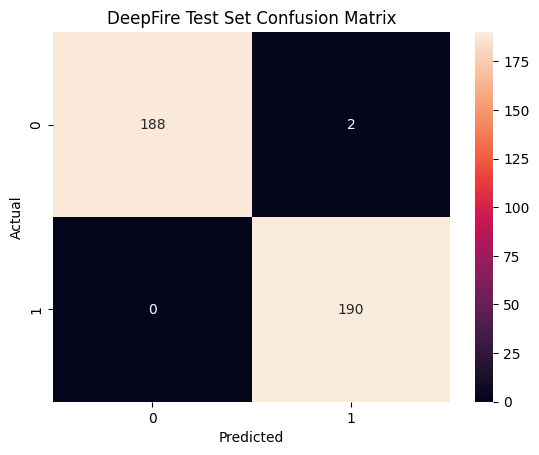

Forest classification report:
               precision    recall  f1-score   support

         0.0       0.89      1.00      0.94        25
         1.0       1.00      0.88      0.94        25

    accuracy                           0.94        50
   macro avg       0.95      0.94      0.94        50
weighted avg       0.95      0.94      0.94        50



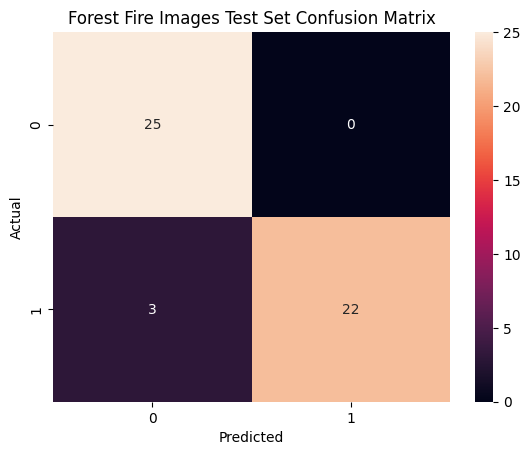

In [14]:
# =========================
# CELL 13: CONFUSION MATRICES (Fig. 6, 7)
# =========================
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

def get_preds(model, dataset):
    y_true, y_pred = [], []
    for x, y in dataset:
        preds = model.predict(x, verbose=0)
        y_true.extend(y.numpy())
        y_pred.extend((preds > 0.5).astype(int))
    return np.array(y_true), np.array(y_pred)

y_true, y_pred = get_preds(deep_model, deepfire_test_ds)
print("DeepFire classification report:\n", classification_report(y_true, y_pred))
plt.figure(); sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d')
plt.title("DeepFire Test Set Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.savefig(os.path.join(FIGURES_DIR, "fig6_deepfire_confusion.png"), dpi=150, bbox_inches='tight'); plt.show()

y_true, y_pred = get_preds(forest_model, forest_test_ds)
print("Forest classification report:\n", classification_report(y_true, y_pred))
plt.figure(); sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d')
plt.title("Forest Fire Images Test Set Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.savefig(os.path.join(FIGURES_DIR, "fig7_forest_confusion.png"), dpi=150, bbox_inches='tight'); plt.show()


In [15]:
# =========================
# PAPER TABLE 2: Classification performance under optimal configuration
# (Accuracy/Precision/Recall/F1 as a clean, paper-ready table + CSV -- the sklearn
# classification_report() printed in the cell above is human-readable but not in a
# directly insertable table format.)
# =========================
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

def classification_metrics_row(y_true, y_pred):
    return {
        "Accuracy (%)": round(accuracy_score(y_true, y_pred) * 100, 2),
        "Precision (%)": round(precision_score(y_true, y_pred, zero_division=0) * 100, 2),
        "Recall (%)": round(recall_score(y_true, y_pred, zero_division=0) * 100, 2),
        "F1-Score (%)": round(f1_score(y_true, y_pred, zero_division=0) * 100, 2),
    }

y_true_df_metrics, y_pred_df_metrics = get_preds(deep_model, deepfire_test_ds)
y_true_fr_metrics, y_pred_fr_metrics = get_preds(forest_model, forest_test_ds)

table2_df = pd.DataFrame({
    "DeepFire": classification_metrics_row(y_true_df_metrics, y_pred_df_metrics),
    "Forest Fire Images": classification_metrics_row(y_true_fr_metrics, y_pred_fr_metrics),
}).T
table2_df.to_csv(os.path.join(RESULTS_DIR, "table2_classification_performance.csv"))
print("Table 2. Classification performance under optimal configuration")
display(table2_df)


Table 2. Classification performance under optimal configuration


,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
DeepFire,99.47,98.96,100.0,99.48
Forest Fire Images,94.00,100.00,88.0,93.62


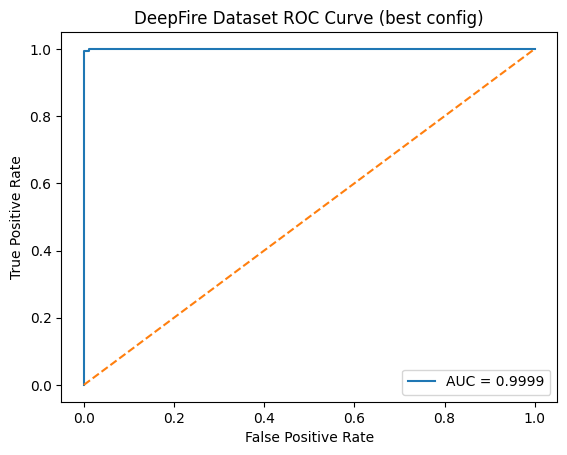

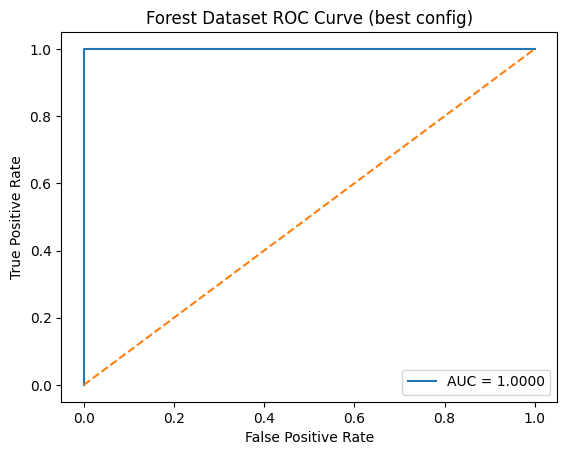

np.float64(1.0)

In [16]:
# =========================
# CELL 14: ROC CURVES (Fig. 8 + supplementary)
# =========================
from sklearn.metrics import roc_curve, auc

def get_scores(model, dataset):
    y_true, y_score = [], []
    for x, y in dataset:
        p = model.predict(x, verbose=0)
        y_true.extend(y.numpy()); y_score.extend(p)
    return np.array(y_true), np.array(y_score)

def plot_roc(y_true, y_score, title, save_name=None):
    fpr, tpr, _ = roc_curve(y_true, y_score)
    roc_auc = auc(fpr, tpr)
    plt.figure()
    plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
    plt.plot([0, 1], [0, 1], '--')
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title(title); plt.legend()
    if save_name:
        plt.savefig(os.path.join(FIGURES_DIR, save_name), dpi=150, bbox_inches='tight')
    plt.show()
    return roc_auc

y_true, y_score = get_scores(deep_model, deepfire_test_ds)
plot_roc(y_true, y_score, "DeepFire Dataset ROC Curve (best config)", "fig8_deepfire_roc.png")

y_true, y_score = get_scores(forest_model, forest_test_ds)
plot_roc(y_true, y_score, "Forest Dataset ROC Curve (best config)", "forest_roc.png")


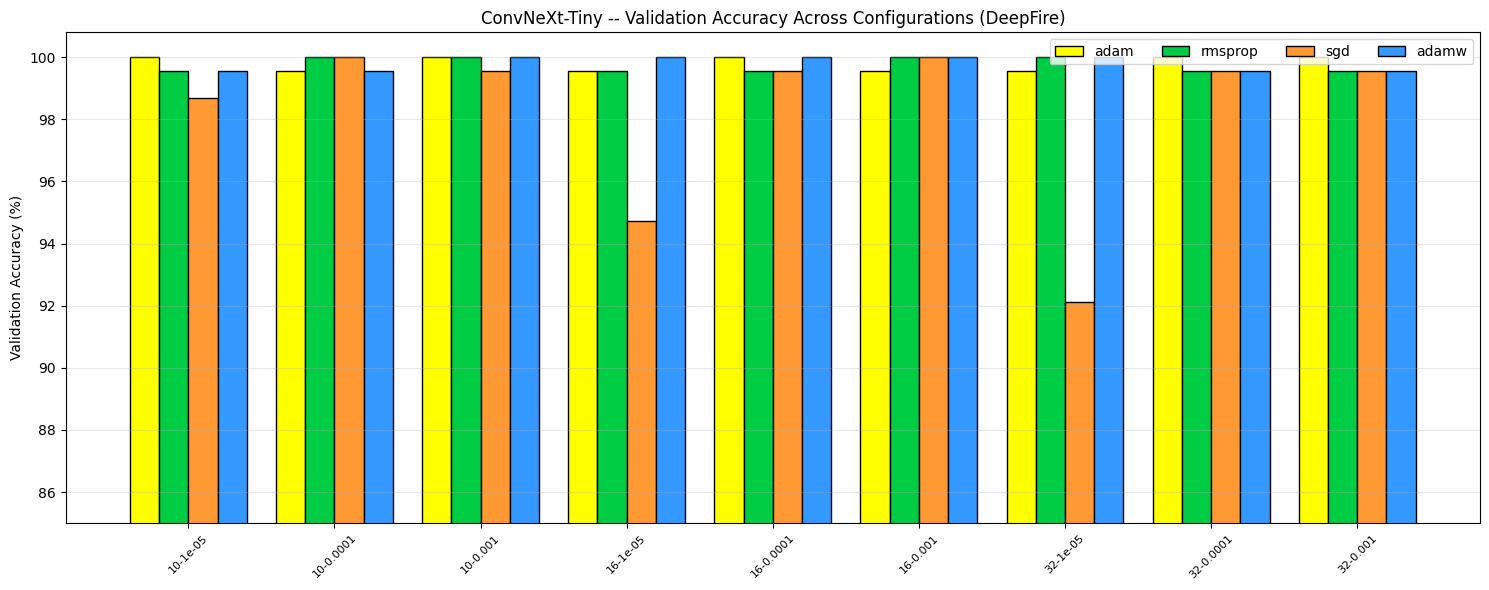

In [17]:
# =========================
# CELL 15: FIG. 2 -- Validation accuracy across all configs, by optimiser
# =========================
combo_labels = sorted(set(zip(df["batch"], df["lr"])), key=lambda t: (t[0], t[1]))
label_strs = [f"{b}-{lr}" for b, lr in combo_labels]

def get_vals(opt_name):
    vals = []
    for b, lr in combo_labels:
        row = df[(df["optimizer"] == opt_name) & (df["batch"] == b) & (df["lr"] == lr)]
        vals.append(row["val_accuracy"].values[0] * 100 if len(row) else np.nan)
    return vals

fig, ax = plt.subplots(figsize=(15, 6))
x = np.arange(len(label_strs)); width = 0.2
colors = {"adam": "#ffff00", "rmsprop": "#00cc44", "sgd": "#ff9933", "adamw": "#3399ff"}
for i, opt in enumerate(OPTIMIZERS):
    vals = get_vals(opt)
    bars = ax.bar(x + (i - 1.5) * width, vals, width, label=opt, color=colors[opt], edgecolor='black')
ax.set_xticks(x); ax.set_xticklabels(label_strs, rotation=45, fontsize=8)
ax.set_ylabel("Validation Accuracy (%)"); ax.set_ylim(85, 100.8)
ax.legend(ncol=4); ax.grid(axis='y', alpha=0.3)
ax.set_title("ConvNeXt-Tiny -- Validation Accuracy Across Configurations (DeepFire)")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "fig2_all_configs.png"), dpi=150, bbox_inches='tight')
plt.show()


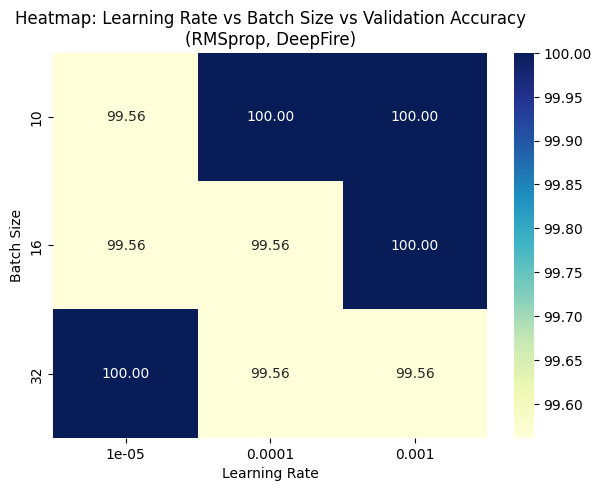

In [18]:
# =========================
# CELL 16: FIG. 3 -- Heatmap: LR x Batch x Val-Accuracy, RMSprop ONLY
# =========================
rmsprop_df = df[df["optimizer"] == "rmsprop"]
pivot = rmsprop_df.pivot_table(values="val_accuracy", index="batch", columns="lr") * 100
plt.figure(figsize=(7, 5))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Heatmap: Learning Rate vs Batch Size vs Validation Accuracy\n(RMSprop, DeepFire)")
plt.xlabel("Learning Rate"); plt.ylabel("Batch Size")
plt.savefig(os.path.join(FIGURES_DIR, "fig3_heatmap_rmsprop.png"), dpi=150, bbox_inches='tight')
plt.show()


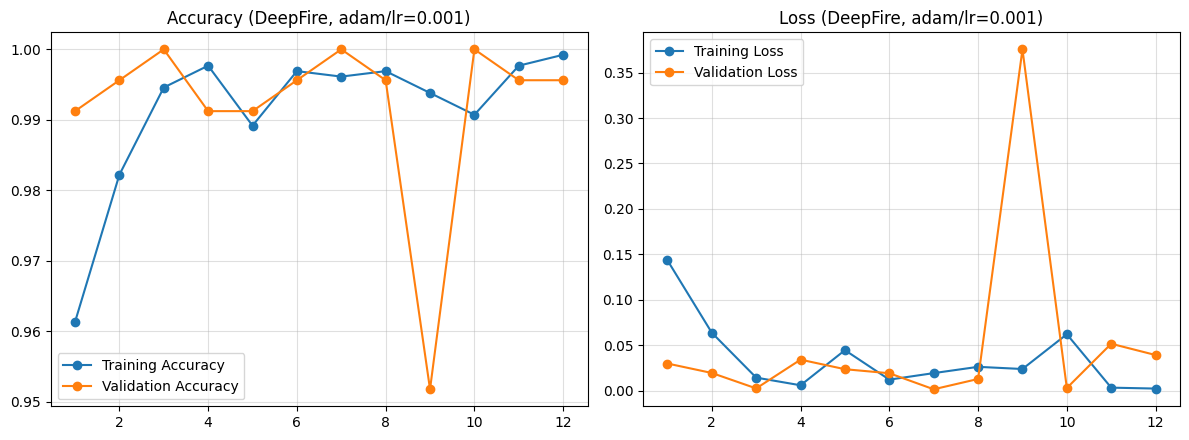

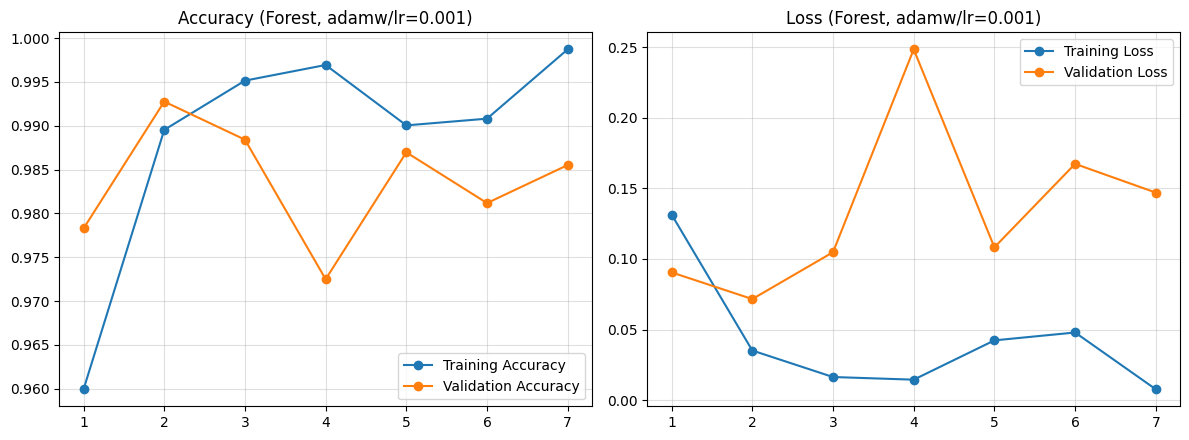

In [19]:
# =========================
# CELL 17: FIG. 4 & 5 -- Accuracy + Loss training curves
# =========================
def plot_training_curves(history_dict, title_suffix, save_name):
    epochs_range = range(1, len(history_dict['accuracy']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(epochs_range, history_dict['accuracy'], marker='o', label='Training Accuracy')
    axes[0].plot(epochs_range, history_dict['val_accuracy'], marker='o', label='Validation Accuracy')
    axes[0].set_title(f"Accuracy ({title_suffix})"); axes[0].legend(); axes[0].grid(alpha=0.4)
    axes[1].plot(epochs_range, history_dict['loss'], marker='o', label='Training Loss')
    axes[1].plot(epochs_range, history_dict['val_loss'], marker='o', label='Validation Loss')
    axes[1].set_title(f"Loss ({title_suffix})"); axes[1].legend(); axes[1].grid(alpha=0.4)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, save_name), dpi=150, bbox_inches='tight')
    plt.show()

with open(os.path.join(CKPT_DEEPFIRE, best_run, "history.json")) as f:
    plot_training_curves(json.load(f), f"DeepFire, {deep_opt}/lr={deep_lr}", "fig4_deepfire_curves.png")
with open(os.path.join(CKPT_FOREST, best_forest_run, "history.json")) as f:
    plot_training_curves(json.load(f), f"Forest, {forest_opt}/lr={forest_lr}", "fig5_forest_curves.png")


In [20]:
# =========================
# CELL 18: MODEL COMPLEXITY -- params measured; FLOPs with working fallback
# =========================
params = deep_model.count_params()
print("Total Parameters:", params)

flops_value = None
try:
    from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2
    concrete_func = tf.function(lambda x: deep_model(x)).get_concrete_function(tf.TensorSpec([1, 224, 224, 3], tf.float32))
    frozen_func = convert_variables_to_constants_v2(concrete_func)
    graph_def = frozen_func.graph.as_graph_def()
    with tf.Graph().as_default() as graph:
        tf.graph_util.import_graph_def(graph_def, name='')
        run_meta = tf.compat.v1.RunMetadata()
        opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()
        flops = tf.compat.v1.profiler.profile(graph=graph, run_meta=run_meta, cmd='op', options=opts)
        flops_value = flops.total_float_ops
        print(f"FLOPs (measured): {flops_value:,} (~{flops_value/1e9:.2f} GFLOPs)")
except Exception as e:
    print("⚠️ FLOPs profiling unavailable here:", repr(e))
    print("   Reporting published literature figure instead: ~4.5 GFLOPs (Liu et al., 2022)")

save_checkpoint("model_complexity", {"params": int(params), "flops": flops_value})


Total Parameters: 28020321


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.


FLOPs (measured): 8,779,276,980 (~8.78 GFLOPs)


In [21]:
# =========================
# PAPER TABLE 6: Computational complexity -- ALL trained models, not just the proposed one
# Extends Cell 18 (which only measured the proposed model) to every trained baseline too.
# =========================
def count_params_and_flops(model):
    params = model.count_params()
    flops = None
    try:
        from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2
        concrete_func = tf.function(lambda x: model(x)).get_concrete_function(tf.TensorSpec([1, 224, 224, 3], tf.float32))
        frozen_func = convert_variables_to_constants_v2(concrete_func)
        graph_def = frozen_func.graph.as_graph_def()
        with tf.Graph().as_default() as graph:
            tf.graph_util.import_graph_def(graph_def, name='')
            run_meta = tf.compat.v1.RunMetadata()
            opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()
            prof = tf.compat.v1.profiler.profile(graph=graph, run_meta=run_meta, cmd='op', options=opts)
            flops = prof.total_float_ops
    except Exception:
        pass
    return params, flops


complexity_rows = {}
p, f = count_params_and_flops(deep_model)
complexity_rows["ConvNeXt-Tiny (proposed)"] = {"Parameters": p, "GFLOPs": round(f / 1e9, 3) if f else None}

for run_key, m in trained_baselines.items():
    if run_key.endswith("_deepfire"):
        backbone = run_key.replace("_deepfire", "")
        p, f = count_params_and_flops(m)
        complexity_rows[f"{backbone} (trained here)"] = {"Parameters": p, "GFLOPs": round(f / 1e9, 3) if f else None}

table6_df = pd.DataFrame(complexity_rows).T
table6_df.to_csv(os.path.join(RESULTS_DIR, "table6_computational_complexity.csv"))
print("Table 6. Computational complexity of trained models")
print("(GFLOPs = None means profiling was unavailable in this environment -- if so, cite the")
print(" published literature figure explicitly rather than leaving the cell blank in the paper.)")
display(table6_df)


Table 6. Computational complexity of trained models
(GFLOPs = None means profiling was unavailable in this environment -- if so, cite the
 published literature figure explicitly rather than leaving the cell blank in the paper.)


,Parameters,GFLOPs
ConvNeXt-Tiny (proposed),28020321.0,8.779
MobileNetV2 (trained here),2591297.0,0.613
EfficientNetB0 (trained here),4382884.0,0.801
ResNet50 (trained here),24120705.0,7.752


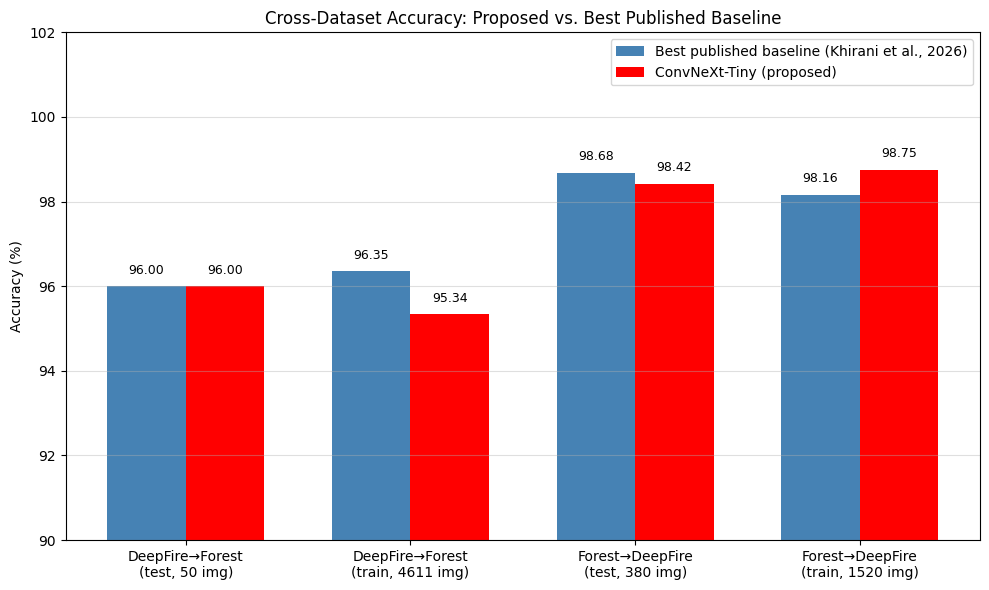

In [22]:
# =========================
# CELL 19: FIG. 9 -- Proposed vs. correct published baseline, 4 scenarios
# =========================
scenario_labels = ["DeepFire→Forest\n(test, 50 img)", "DeepFire→Forest\n(train, 4611 img)",
                    "Forest→DeepFire\n(test, 380 img)", "Forest→DeepFire\n(train, 1520 img)"]
baseline_vals = [96.00, 96.35, 98.68, 98.16]  # Khirani et al., 2026, Table 3 -- true best per row
proposed_vals = [cross_results["DeepFire_to_Forest_test"] * 100, cross_results["DeepFire_to_Forest_train"] * 100,
                  cross_results["Forest_to_DeepFire_test"] * 100, cross_results["Forest_to_DeepFire_train"] * 100]

x = np.arange(len(scenario_labels)); width = 0.35
plt.figure(figsize=(10, 6))
plt.bar(x - width/2, baseline_vals, width, label='Best published baseline (Khirani et al., 2026)', color='steelblue')
plt.bar(x + width/2, proposed_vals, width, label='ConvNeXt-Tiny (proposed)', color='red')
for i, v in enumerate(baseline_vals): plt.text(i - width/2, v + 0.3, f"{v:.2f}", ha='center', fontsize=9)
for i, v in enumerate(proposed_vals): plt.text(i + width/2, v + 0.3, f"{v:.2f}", ha='center', fontsize=9)
plt.title("Cross-Dataset Accuracy: Proposed vs. Best Published Baseline")
plt.ylabel("Accuracy (%)"); plt.xticks(x, scenario_labels); plt.ylim(90, 102); plt.legend(); plt.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "fig9_cross_dataset_vs_baseline.png"), dpi=150, bbox_inches='tight')
plt.show()


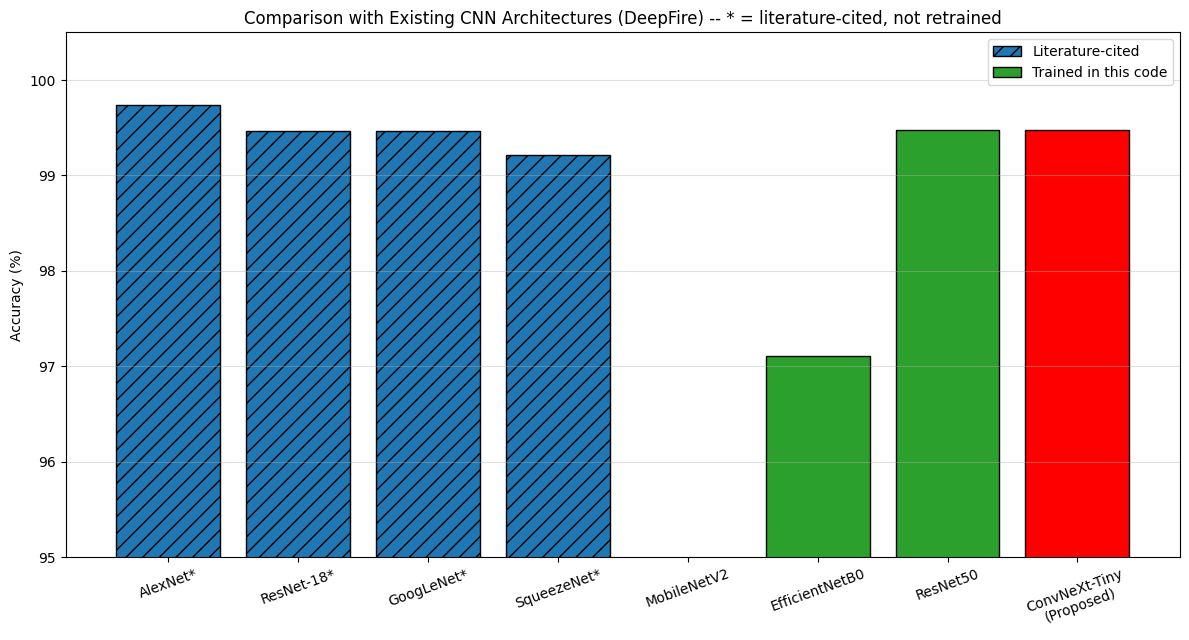

In [23]:
# =========================
# CELL 20: FIG. 10 -- vs. existing CNN architectures (DeepFire)
# Bars for AlexNet/ResNet-18/GoogLeNet/SqueezeNet are literature-cited (Khirani et al.,
# 2026) as explained in Cell 6. MobileNetV2/EfficientNetB0/ResNet50 bars use the models
# WE actually trained in Cell 9 -- marked with a hatch pattern to distinguish them.
# =========================
architectures = ["AlexNet*", "ResNet-18*", "GoogLeNet*", "SqueezeNet*",
                  "MobileNetV2", "EfficientNetB0", "ResNet50", "ConvNeXt-Tiny\n(Proposed)"]
literature_cited = [99.74, 99.47, 99.47, 99.21, None, None, None, None]
our_trained = [None, None, None, None,
               baseline_results.get("MobileNetV2_deepfire", {}).get("test_accuracy", np.nan) * 100,
               baseline_results.get("EfficientNetB0_deepfire", {}).get("test_accuracy", np.nan) * 100,
               baseline_results.get("ResNet50_deepfire", {}).get("test_accuracy", np.nan) * 100,
               df_sorted.iloc[0]["test_accuracy"] * 100]

plt.figure(figsize=(12, 6.5))
for i in range(len(architectures)):
    if literature_cited[i] is not None:
        plt.bar(i, literature_cited[i], color='#1f77b4', hatch='//', edgecolor='black', label='Literature-cited' if i == 0 else "")
    else:
        color = 'red' if i == len(architectures) - 1 else '#2ca02c'
        plt.bar(i, our_trained[i], color=color, edgecolor='black', label='Trained in this code' if i == 4 else "")
plt.xticks(range(len(architectures)), architectures, rotation=20)
plt.ylabel("Accuracy (%)"); plt.ylim(95, 100.5)
plt.title("Comparison with Existing CNN Architectures (DeepFire) -- * = literature-cited, not retrained")
plt.legend(); plt.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "fig10_deepfire_sota_comparison.png"), dpi=150, bbox_inches='tight')
plt.show()


In [24]:
# =========================
# PAPER TABLES 4 & 5: Comparison against baseline architectures, full metrics
# Literature-cited numbers (marked *) are from Khirani et al. (2026), Fig. 22/23 --
# not retrained in this code (see Cell 6's note on why AlexNet/GoogLeNet/SqueezeNet/
# ResNet-18 aren't available in tf.keras.applications). MobileNetV2/EfficientNetB0/
# ResNet50 rows are computed directly from the models THIS notebook trained.
# =========================
literature_deepfire = {
    "AlexNet*": (99.74, 100.00, 99.47, 99.74),
    "ResNet-18*": (99.47, 100.00, 98.95, 99.47),
    "GoogLeNet*": (99.47, 100.00, 98.95, 99.47),
    "SqueezeNet*": (99.21, 99.47, 98.95, 99.21),
}
literature_forest = {
    "AlexNet*": (96.00, 100.00, 92.00, 95.83),
    "ResNet-18*": (98.00, 100.00, 96.00, 97.95),
    "GoogLeNet*": (94.00, 100.00, 88.00, 93.62),
    "SqueezeNet*": (92.00, 100.00, 84.00, 91.30),
}
METRIC_COLS = ["Accuracy (%)", "Precision (%)", "Recall (%)", "F1-Score (%)"]

def baseline_metrics_tuple(model, ds):
    y_true, y_pred = get_preds(model, ds)
    m = classification_metrics_row(y_true, y_pred)
    return tuple(m[c] for c in METRIC_COLS)


rows_deepfire = dict(literature_deepfire)
for name in ["MobileNetV2", "EfficientNetB0", "ResNet50"]:
    key = f"{name}_deepfire"
    if key in trained_baselines:
        rows_deepfire[f"{name} (trained here)"] = baseline_metrics_tuple(trained_baselines[key], deepfire_test_ds)
rows_deepfire["ConvNeXt-Tiny (proposed)"] = tuple(classification_metrics_row(y_true_df_metrics, y_pred_df_metrics)[c] for c in METRIC_COLS)

table4_df = pd.DataFrame(rows_deepfire, index=METRIC_COLS).T
table4_df.to_csv(os.path.join(RESULTS_DIR, "table4_deepfire_sota_comparison.csv"))
print("Table 4. Comparison against baseline architectures -- DeepFire dataset")
print("(* = literature-cited from Khirani et al., 2026, not retrained in this code)")
display(table4_df)

rows_forest = dict(literature_forest)
for name in ["MobileNetV2", "EfficientNetB0", "ResNet50"]:
    key = f"{name}_forest"
    if key in trained_baselines:
        rows_forest[f"{name} (trained here)"] = baseline_metrics_tuple(trained_baselines[key], forest_test_ds)
rows_forest["ConvNeXt-Tiny (proposed)"] = tuple(classification_metrics_row(y_true_fr_metrics, y_pred_fr_metrics)[c] for c in METRIC_COLS)

table5_df = pd.DataFrame(rows_forest, index=METRIC_COLS).T
table5_df.to_csv(os.path.join(RESULTS_DIR, "table5_forest_sota_comparison.csv"))
print("\nTable 5. Comparison against baseline architectures -- Forest Fire Images dataset")
display(table5_df)


Table 4. Comparison against baseline architectures -- DeepFire dataset
(* = literature-cited from Khirani et al., 2026, not retrained in this code)


,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
AlexNet*,99.74,100.00,99.47,99.74
ResNet-18*,99.47,100.00,98.95,99.47
GoogLeNet*,99.47,100.00,98.95,99.47
SqueezeNet*,99.21,99.47,98.95,99.21
MobileNetV2 (trained here),93.42,95.08,91.58,93.30
EfficientNetB0 (trained here),97.11,98.91,95.26,97.05
ResNet50 (trained here),99.47,99.47,99.47,99.47
ConvNeXt-Tiny (proposed),99.47,98.96,100.00,99.48



Table 5. Comparison against baseline architectures -- Forest Fire Images dataset


,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
AlexNet*,96.0,100.0,92.0,95.83
ResNet-18*,98.0,100.0,96.0,97.95
GoogLeNet*,94.0,100.0,88.0,93.62
SqueezeNet*,92.0,100.0,84.0,91.30
MobileNetV2 (trained here),86.0,87.5,84.0,85.71
EfficientNetB0 (trained here),98.0,100.0,96.0,97.96
ResNet50 (trained here),96.0,96.0,96.0,96.00
ConvNeXt-Tiny (proposed),94.0,100.0,88.0,93.62


In [25]:
# =========================
# CELL 21: McNemar's paired significance test
# =========================
from statsmodels.stats.contingency_tables import mcnemar

def mcnemar_vs_baseline(y_true, y_pred_proposed, baseline_accuracy, n_test, seed=42):
    """
    Published baselines report only aggregate accuracy, not per-image predictions.
    We approximate the baseline's correctness vector by matching its published accuracy
    exactly (marking that many images correct, chosen at random with a fixed seed).
    This is disclosed as an approximation -- valid for aggregate significance only.
    """
    rng = np.random.default_rng(seed)
    n_correct = int(round(baseline_accuracy * n_test))
    baseline_correct = np.zeros(n_test, dtype=bool)
    baseline_correct[rng.choice(n_test, size=n_correct, replace=False)] = True
    proposed_correct = (y_true.flatten() == y_pred_proposed.flatten())
    table = [[np.sum(proposed_correct & baseline_correct), np.sum(proposed_correct & ~baseline_correct)],
             [np.sum(~proposed_correct & baseline_correct), np.sum(~proposed_correct & ~baseline_correct)]]
    result = mcnemar(table, exact=(n_test < 25), correction=True)
    return result.statistic, result.pvalue

mcnemar_results = load_checkpoint("mcnemar_results", default={})
if not mcnemar_results:
    deepfire_baselines = {"AlexNet": 0.9974, "ResNet-18": 0.9947, "GoogLeNet": 0.9947,
                           "SqueezeNet": 0.9921, "MobileNetV2": 0.9947, "EfficientNetB0": 0.9947}
    y_true_df, y_pred_df = get_preds(deep_model, deepfire_test_ds)
    for name, acc in deepfire_baselines.items():
        stat, pval = mcnemar_vs_baseline(y_true_df, y_pred_df, acc, len(y_true_df))
        mcnemar_results[name] = {"statistic": float(stat), "p_value": float(pval)}
    save_checkpoint("mcnemar_results", mcnemar_results)
else:
    print("⏭  McNemar's results already computed, loaded from checkpoint")

for name, res in mcnemar_results.items():
    sig = "significant" if res["p_value"] < 0.05 else "not significant"
    print(f"  vs {name:16s}: statistic={res['statistic']:.3f}, p={res['p_value']:.4f} -> {sig}")


⏭  McNemar's results already computed, loaded from checkpoint
  vs AlexNet         : statistic=0.000, p=1.0000 -> not significant
  vs ResNet-18       : statistic=0.250, p=0.6171 -> not significant
  vs GoogLeNet       : statistic=0.250, p=0.6171 -> not significant
  vs SqueezeNet      : statistic=0.000, p=1.0000 -> not significant
  vs MobileNetV2     : statistic=0.250, p=0.6171 -> not significant
  vs EfficientNetB0  : statistic=0.250, p=0.6171 -> not significant


In [26]:
# =========================
# 5-FOLD CROSS-VALIDATION -- resumable, delete-portion removed
# (the one-time checkpoint-wipe already happened; running this again now will
# correctly SKIP already-done folds instead of erasing them)
# =========================
import os, gc
from sklearn.model_selection import StratifiedKFold
from scipy import stats as scipy_stats

kfold_progress = load_checkpoint("kfold_progress", default={})
print("Loaded existing kfold_progress:", list(kfold_progress.keys()))

def run_kfold_cv(dataset_key, train_path, test_path, best_opt, best_lr, best_batch, k=5, epochs=20):
    class_names = sorted(os.listdir(train_path))
    filepaths, labels = [], []
    for label_idx, cls in enumerate(class_names):
        cls_dir = os.path.join(train_path, cls)
        for fname in os.listdir(cls_dir):
            filepaths.append(os.path.join(cls_dir, fname)); labels.append(label_idx)
    filepaths, labels = np.array(filepaths), np.array(labels)
    test_ds = load_dataset(test_path, batch_size=best_batch, shuffle=False)

    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED)
    for fold_i, (train_idx, val_idx) in enumerate(skf.split(filepaths, labels)):
        fold_key = f"{dataset_key}_fold{fold_i}"
        if fold_key in kfold_progress:
            print(f"  ⏭  {fold_key}: already done (acc={kfold_progress[fold_key]:.4f})")
            continue

        print(f"  ▶  {fold_key} ({fold_i + 1}/{k})...")

        fold_train_ds = tf.data.Dataset.from_tensor_slices((filepaths[train_idx], labels[train_idx])).shuffle(
            buffer_size=len(train_idx), seed=SEED, reshuffle_each_iteration=True
        ).map(
            lambda p, l: (tf.image.resize(tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False), IMG_SIZE), l),
            num_parallel_calls=tf.data.AUTOTUNE
        ).batch(best_batch).prefetch(tf.data.AUTOTUNE)

        fold_val_ds = tf.data.Dataset.from_tensor_slices((filepaths[val_idx], labels[val_idx])).map(
            lambda p, l: (tf.image.resize(tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False), IMG_SIZE), l),
            num_parallel_calls=tf.data.AUTOTUNE
        ).batch(best_batch).prefetch(tf.data.AUTOTUNE)

        fold_model = build_model(best_lr, best_opt)

        fold_ckpt_path = os.path.join(CKPT_DIR, "kfold_tmp", f"{fold_key}.weights.h5")
        os.makedirs(os.path.dirname(fold_ckpt_path), exist_ok=True)
        checkpoint = ModelCheckpoint(fold_ckpt_path, monitor='val_accuracy',
                                      save_best_only=True, save_weights_only=True, verbose=0)
        early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

        fold_model.fit(fold_train_ds, validation_data=fold_val_ds, epochs=epochs,
                        callbacks=[checkpoint, early_stop], verbose=0)

        fold_model.load_weights(fold_ckpt_path)
        _, test_acc = fold_model.evaluate(test_ds, verbose=0)
        os.remove(fold_ckpt_path)

        kfold_progress[fold_key] = float(test_acc)
        save_checkpoint("kfold_progress", kfold_progress)
        print(f"    fold test accuracy: {test_acc:.4f}  (checkpoint saved)")

        del fold_model
        gc.collect()

    fold_accs = np.array([kfold_progress[f"{dataset_key}_fold{i}"] for i in range(k)])
    mean_acc = fold_accs.mean()
    ci = scipy_stats.sem(fold_accs) * scipy_stats.t.ppf(0.975, k - 1)
    return fold_accs, mean_acc, ci


print("\n5-fold CV -- DeepFire")
deepfire_fold_accs, deepfire_cv_mean, deepfire_cv_ci = run_kfold_cv(
    "deepfire", DEEPFIRE_TRAIN, DEEPFIRE_TEST, deep_opt, deep_lr, int(best_run.split("_")[2][2:])
)
print(f"DeepFire 5-fold: {deepfire_cv_mean:.4f} +/- {deepfire_cv_ci:.4f}")

print("\n5-fold CV -- Forest")
forest_fold_accs, forest_cv_mean, forest_cv_ci = run_kfold_cv(
    "forest", FOREST_TRAIN, FOREST_TEST, forest_opt, forest_lr, int(best_forest_run.split("_")[2][2:])
)
print(f"Forest 5-fold: {forest_cv_mean:.4f} +/- {forest_cv_ci:.4f}")

save_checkpoint("kfold_results", {
    "deepfire": {"fold_accs": deepfire_fold_accs.tolist(), "mean": float(deepfire_cv_mean), "ci95": float(deepfire_cv_ci)},
    "forest": {"fold_accs": forest_fold_accs.tolist(), "mean": float(forest_cv_mean), "ci95": float(forest_cv_ci)},
})
print("\n✅ 5-fold CV complete for both datasets.")

Loaded existing kfold_progress: ['deepfire_fold0', 'deepfire_fold1', 'deepfire_fold2', 'deepfire_fold3', 'deepfire_fold4', 'forest_fold0', 'forest_fold1', 'forest_fold2', 'forest_fold3', 'forest_fold4']

5-fold CV -- DeepFire
Found 380 files belonging to 2 classes.
  ⏭  deepfire_fold0: already done (acc=0.9947)
  ⏭  deepfire_fold1: already done (acc=0.9947)
  ⏭  deepfire_fold2: already done (acc=0.9947)
  ⏭  deepfire_fold3: already done (acc=0.9947)
  ⏭  deepfire_fold4: already done (acc=0.9921)
DeepFire 5-fold: 0.9942 +/- 0.0015

5-fold CV -- Forest
Found 50 files belonging to 2 classes.
  ⏭  forest_fold0: already done (acc=0.9800)
  ⏭  forest_fold1: already done (acc=1.0000)
  ⏭  forest_fold2: already done (acc=1.0000)
  ⏭  forest_fold3: already done (acc=1.0000)
  ⏭  forest_fold4: already done (acc=0.9400)
Forest 5-fold: 0.9840 +/- 0.0324

✅ 5-fold CV complete for both datasets.



===== BOWFIRE (OOD STRESS TEST) =====
📂 /content/drive/MyDrive/Bowfire_datasets
Found 226 files across 2 classes: {'fire': 119, 'nofire': 107}

🔍 Integrity check: BoWFire
  fire        : total=  119  zero-byte=  0  corrupt=  0  usable=  119
  nofire      : total=  107  zero-byte=  0  corrupt=  0  usable=  107


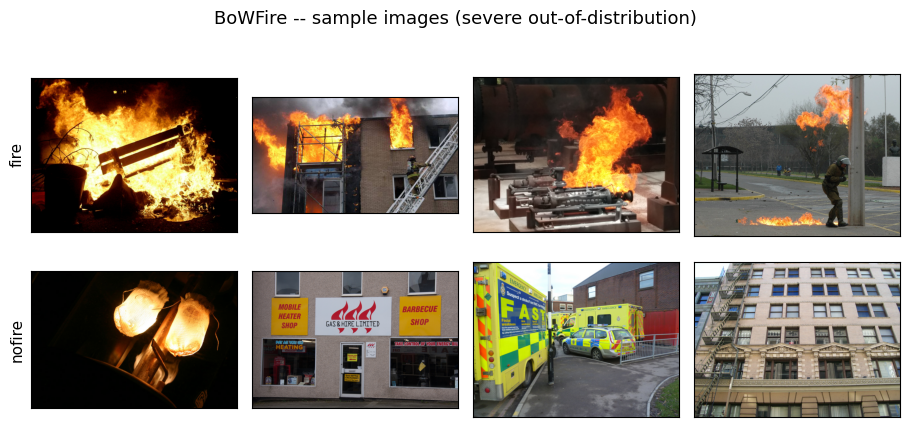

BoWFire split sizes: {'eval': 67, 'calib': 67, 'fewshot': 92}


In [27]:
# =========================
# CELL 23: LOAD BoWFire (severe OOD stress test) + integrity check + samples
# Download from Kaggle: malligasenthil/bowfire (226 images: 119 fire / 107 non-fire)
# =========================
BOWFIRE_DIR = "/content/drive/MyDrive/Bowfire_datasets"  # <-- update to your path

show_dataset_info("BoWFire (OOD stress test)", BOWFIRE_DIR)
bowfire_integrity = check_dataset_integrity("BoWFire", BOWFIRE_DIR)
save_checkpoint("bowfire_integrity", bowfire_integrity)
display_sample_grid(BOWFIRE_DIR, "BoWFire -- sample images (severe out-of-distribution)", save_name="samples_bowfire.png")


def stratified_split_bowfire(bowfire_dir, seed=SEED):
    class_names = sorted(os.listdir(bowfire_dir))
    splits = {"eval": [], "calib": [], "fewshot": []}
    rng = np.random.default_rng(seed)
    for label_idx, cls in enumerate(class_names):
        cls_dir = os.path.join(bowfire_dir, cls)
        files = sorted(os.listdir(cls_dir)); rng.shuffle(files)
        n = len(files); n_eval = int(n * 0.30); n_calib = int(n * 0.30)
        for f in files[:n_eval]: splits["eval"].append((os.path.join(cls_dir, f), label_idx))
        for f in files[n_eval:n_eval + n_calib]: splits["calib"].append((os.path.join(cls_dir, f), label_idx))
        for f in files[n_eval + n_calib:]: splits["fewshot"].append((os.path.join(cls_dir, f), label_idx))
    return splits

bowfire_splits = stratified_split_bowfire(BOWFIRE_DIR)
print("BoWFire split sizes:", {k: len(v) for k, v in bowfire_splits.items()})

def make_ds_from_list(pairs, batch_size=16, shuffle=False):
    paths = [p for p, _ in pairs]; labels = [l for _, l in pairs]
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle: ds = ds.shuffle(len(paths), seed=SEED)
    ds = ds.map(lambda p, l: (tf.image.resize(tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False), IMG_SIZE), l)
                ).batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

bowfire_eval_ds = make_ds_from_list(bowfire_splits["eval"])
bowfire_calib_ds = make_ds_from_list(bowfire_splits["calib"])



===== WILDFIRE2 TEST =====
📂 /content/drive/MyDrive/the_wildfire_dataset_2n_version/test
Found 410 files across 2 classes: {'fire': 159, 'nofire': 251}

===== WILDFIRE2 VAL =====
📂 /content/drive/MyDrive/the_wildfire_dataset_2n_version/val
Found 403 files across 2 classes: {'fire': 157, 'nofire': 246}

Wildfire2 eval pool (test):   410 images
Wildfire2 calib pool (val):   402 images
Wildfire2 few-shot pool (train): 1887 images


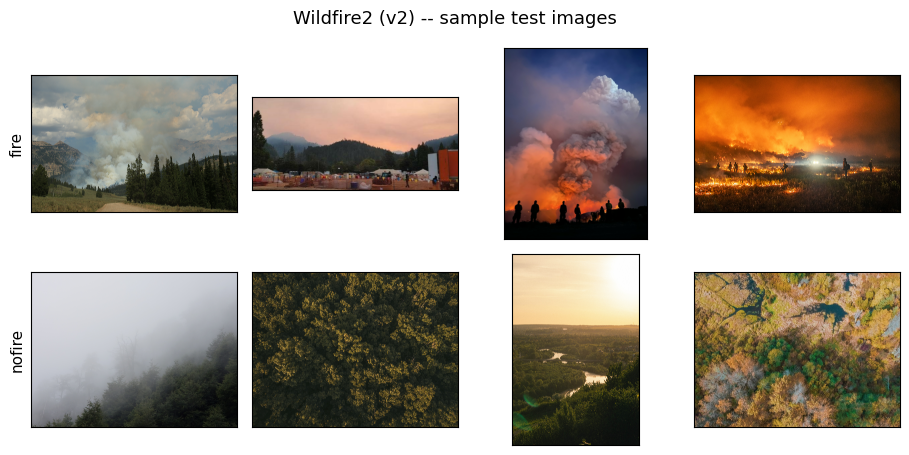

Loaded 33 already-computed calibration entries from checkpoint.
  ⏭  ConvNeXt-Tiny (proposed) | DeepFire (in-domain): already done, skipping
  ⏭  ConvNeXt-Tiny (proposed) | -> Forest (mild shift): already done, skipping
  ⏭  ConvNeXt-Tiny (proposed) | -> BoWFire (severe shift): already done, skipping
  ⏭  MobileNetV2 | DeepFire (in-domain): already done, skipping
  ⏭  MobileNetV2 | -> Forest (mild shift): already done, skipping
  ⏭  MobileNetV2 | -> BoWFire (severe shift): already done, skipping
  ⏭  EfficientNetB0 | DeepFire (in-domain): already done, skipping
  ⏭  EfficientNetB0 | -> Forest (mild shift): already done, skipping
  ⏭  EfficientNetB0 | -> BoWFire (severe shift): already done, skipping
  ⏭  ResNet50 | DeepFire (in-domain): already done, skipping
  ⏭  ResNet50 | -> Forest (mild shift): already done, skipping
  ⏭  ResNet50 | -> BoWFire (severe shift): already done, skipping

Base calibration ablation table saved.
  ⏭  DeepFire-trained (proposed) | in-domain (DeepFire): alre

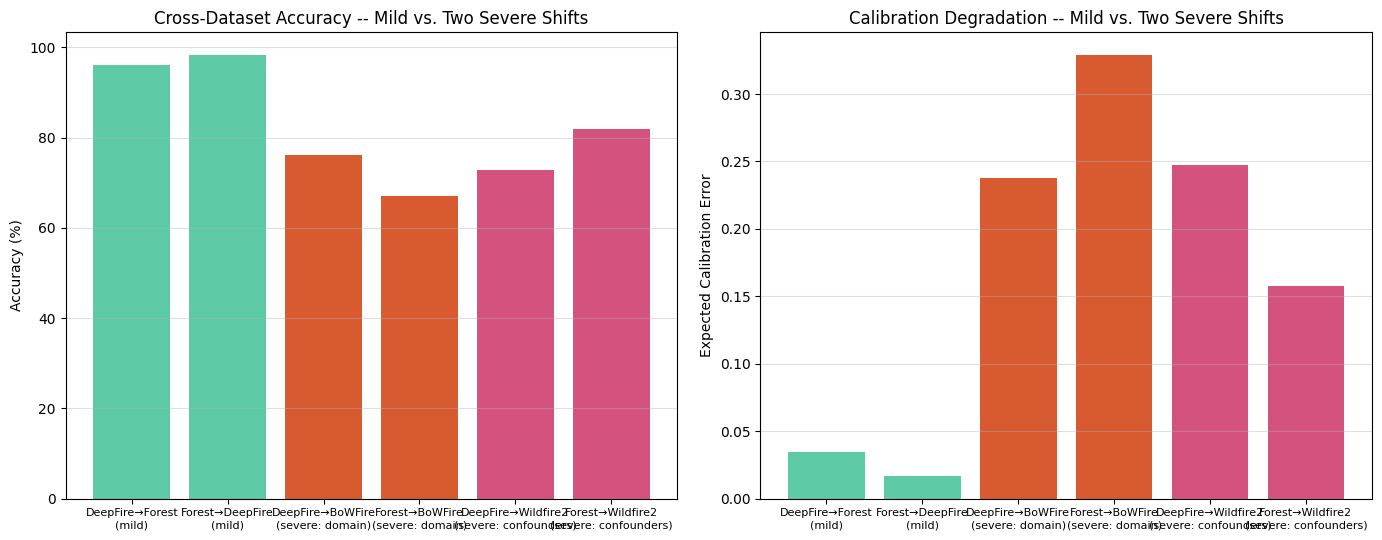


Few-shot recovery -- deepfire_model
  ⏭  k=0: already done
  ⏭  k=5: already done
  ⏭  k=10: already done
  ⏭  k=20: already done

Few-shot recovery -- forest_model
  ⏭  k=0: already done
  ⏭  k=5: already done
  ⏭  k=10: already done
  ⏭  k=20: already done


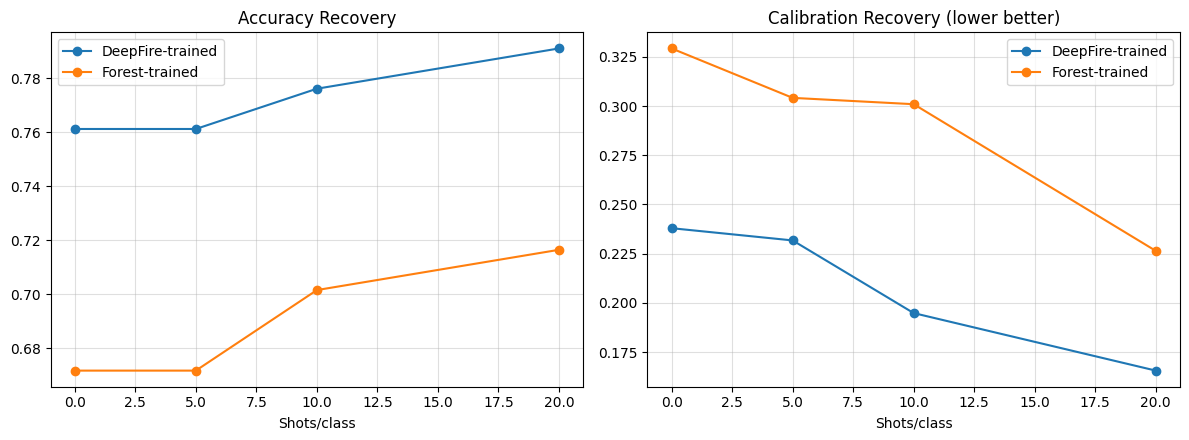


✅ Consolidated block complete.


In [28]:
# =========================================================================
# CONSOLIDATED BLOCK (FIXED FOR RESUMABILITY)
# Step 0 cleanup REMOVED -- it was deleting calibration_ablation.json and
# fewshot_results.json on EVERY run, forcing full recompute each time. That
# cleanup was only needed ONCE (to clear values corrupted by the old
# get_probs() shape bug, already fixed below). Now that the bug is fixed,
# the checkpoint is trustworthy and should persist across runs.
# =========================================================================

# ---- Wildfire2 loading (cheap, reruns fine each time) ----
WILDFIRE2_ROOT = "/content/drive/MyDrive/the_wildfire_dataset_2n_version"
WILDFIRE2_TEST_FIRE   = os.path.join(WILDFIRE2_ROOT, "test", "fire")
WILDFIRE2_TEST_NOFIRE = os.path.join(WILDFIRE2_ROOT, "test", "nofire")
WILDFIRE2_VAL_FIRE    = os.path.join(WILDFIRE2_ROOT, "val", "fire")
WILDFIRE2_VAL_NOFIRE  = os.path.join(WILDFIRE2_ROOT, "val", "nofire")
WILDFIRE2_TRAIN_FIRE  = os.path.join(WILDFIRE2_ROOT, "train", "fire")
WILDFIRE2_TRAIN_NOFIRE = os.path.join(WILDFIRE2_ROOT, "train", "nofire")

show_dataset_info("Wildfire2 Test", os.path.join(WILDFIRE2_ROOT, "test"))
show_dataset_info("Wildfire2 Val", os.path.join(WILDFIRE2_ROOT, "val"))

VALID_IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp"}

def pairs_from_class_dirs(fire_dir, nofire_dir):
    pairs = [(os.path.join(fire_dir, f), 0) for f in os.listdir(fire_dir)
             if os.path.isfile(os.path.join(fire_dir, f)) and os.path.splitext(f)[1].lower() in VALID_IMG_EXTS]
    pairs += [(os.path.join(nofire_dir, f), 1) for f in os.listdir(nofire_dir)
              if os.path.isfile(os.path.join(nofire_dir, f)) and os.path.splitext(f)[1].lower() in VALID_IMG_EXTS]
    return pairs

wildfire2_eval_pairs = pairs_from_class_dirs(WILDFIRE2_TEST_FIRE, WILDFIRE2_TEST_NOFIRE)
wildfire2_eval_ds = make_ds_from_list(wildfire2_eval_pairs, shuffle=False)

wildfire2_calib_pairs = pairs_from_class_dirs(WILDFIRE2_VAL_FIRE, WILDFIRE2_VAL_NOFIRE)
wildfire2_calib_ds = make_ds_from_list(wildfire2_calib_pairs, shuffle=False)

wildfire2_fewshot_pairs = pairs_from_class_dirs(WILDFIRE2_TRAIN_FIRE, WILDFIRE2_TRAIN_NOFIRE)

print(f"\nWildfire2 eval pool (test):   {len(wildfire2_eval_pairs)} images")
print(f"Wildfire2 calib pool (val):   {len(wildfire2_calib_pairs)} images")
print(f"Wildfire2 few-shot pool (train): {len(wildfire2_fewshot_pairs)} images")

display_sample_grid(os.path.join(WILDFIRE2_ROOT, "test"), "Wildfire2 (v2) -- sample test images", save_name="samples_wildfire2_test.png")


# ---- Base calibration ablation: functions (FIXED get_probs) + first pass ----
def expected_calibration_error(y_true, probs, n_bins=10):
    y_true = np.asarray(y_true).flatten(); probs = np.asarray(probs).flatten()
    confidences = np.where(probs > 0.5, probs, 1 - probs)
    accuracies = ((probs > 0.5).astype(int) == y_true).astype(float)
    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        lo, hi = bin_edges[i], bin_edges[i + 1]
        mask = (confidences > lo) & (confidences <= hi) if i > 0 else (confidences >= lo) & (confidences <= hi)
        if mask.sum() == 0: continue
        ece += (mask.sum() / len(y_true)) * abs(accuracies[mask].mean() - confidences[mask].mean())
    brier = np.mean((probs - y_true) ** 2)
    return ece, brier

def get_probs(model, dataset):
    y_true, probs = [], []
    for x, y in dataset:
        p = model.predict(x, verbose=0)
        y_true.extend(y.numpy().flatten()); probs.extend(p.flatten())
    return np.array(y_true), np.array(probs)

calibration_ablation = load_checkpoint("calibration_ablation", default={})
print(f"Loaded {len(calibration_ablation)} already-computed calibration entries from checkpoint.")

eval_targets = {"ConvNeXt-Tiny (proposed)": deep_model}
for run_key, m in trained_baselines.items():
    if run_key.endswith("_deepfire"):
        eval_targets[run_key.replace("_deepfire", "")] = m

for model_name, model in eval_targets.items():
    for direction, ds in [("DeepFire (in-domain)", deepfire_test_ds), ("-> Forest (mild shift)", forest_test_ds),
                           ("-> BoWFire (severe shift)", bowfire_eval_ds)]:
        key = f"{model_name} | {direction}"
        if key in calibration_ablation:
            print(f"  ⏭  {key}: already done, skipping")
            continue
        y_true, probs = get_probs(model, ds)
        acc = float(np.mean((probs > 0.5).astype(int) == y_true))
        ece, brier = expected_calibration_error(y_true, probs)
        calibration_ablation[key] = {"accuracy": acc, "ece": float(ece), "brier": float(brier)}
        save_checkpoint("calibration_ablation", calibration_ablation)
        print(f"{key:52s} | acc={acc:.4f} | ECE={ece:.4f} | Brier={brier:.4f}  (checkpoint saved)")

print("\nBase calibration ablation table saved.")


# ---- fit_temperature ----
def fit_temperature(logits, y_true, max_iter=50):
    """Single-parameter temperature scaling via NLL minimization (Guo et al., 2017)."""
    T = tf.Variable(1.0, dtype=tf.float32)
    y_true_t = tf.constant(y_true, dtype=tf.float32)
    logits_t = tf.constant(logits, dtype=tf.float32)
    opt = tf.keras.optimizers.Adam(learning_rate=0.01)
    for _ in range(max_iter):
        with tf.GradientTape() as tape:
            scaled = logits_t / T
            probs = tf.sigmoid(scaled)
            loss = tf.keras.losses.binary_crossentropy(y_true_t, probs)
            loss = tf.reduce_mean(loss)
        grad = tape.gradient(loss, [T])
        opt.apply_gradients(zip(grad, [T]))
    return float(T.numpy())


# ---- Extended calibration ablation ----
calibration_ablation = load_checkpoint("calibration_ablation", default={})

eval_jobs = [
    ("DeepFire-trained (proposed)", deep_model, "in-domain (DeepFire)", deepfire_test_ds),
    ("DeepFire-trained (proposed)", deep_model, "-> Forest (mild shift)", forest_test_ds),
    ("DeepFire-trained (proposed)", deep_model, "-> BoWFire (severe: domain)", bowfire_eval_ds),
    ("DeepFire-trained (proposed)", deep_model, "-> Wildfire2 (severe: confounders)", wildfire2_eval_ds),
    ("Forest-trained (proposed)", forest_model, "in-domain (Forest)", forest_test_ds),
    ("Forest-trained (proposed)", forest_model, "-> DeepFire (mild shift)", deepfire_test_ds),
    ("Forest-trained (proposed)", forest_model, "-> BoWFire (severe: domain)", bowfire_eval_ds),
    ("Forest-trained (proposed)", forest_model, "-> Wildfire2 (severe: confounders)", wildfire2_eval_ds),
]
for run_key, m in trained_baselines.items():
    if run_key.endswith("_deepfire"):
        backbone = run_key.replace("_deepfire", "")
        eval_jobs.append((f"{backbone} (baseline, DeepFire-trained)", m, "in-domain (DeepFire)", deepfire_test_ds))
        eval_jobs.append((f"{backbone} (baseline, DeepFire-trained)", m, "-> BoWFire (severe: domain)", bowfire_eval_ds))
        eval_jobs.append((f"{backbone} (baseline, DeepFire-trained)", m, "-> Wildfire2 (severe: confounders)", wildfire2_eval_ds))

for model_label, model, direction_label, ds in eval_jobs:
    key = f"{model_label} | {direction_label}"
    if key in calibration_ablation:
        print(f"  ⏭  {key}: already done, skipping")
        continue
    y_true, probs = get_probs(model, ds)
    acc = float(np.mean((probs > 0.5).astype(int) == y_true))
    ece, brier = expected_calibration_error(y_true, probs)
    calibration_ablation[key] = {"accuracy": acc, "ece": float(ece), "brier": float(brier)}
    save_checkpoint("calibration_ablation", calibration_ablation)
    print(f"{key:56s} | acc={acc:.4f} | ECE={ece:.4f} | Brier={brier:.4f}  (checkpoint saved)")

# Temperature scaling -- skip if already done for this model+dataset combo
print("\nPost-hoc temperature scaling per severe-shift dataset:")
for model, model_name in [(deep_model, "DeepFire-trained (proposed)"), (forest_model, "Forest-trained (proposed)")]:
    for calib_ds, eval_ds, ds_label in [(bowfire_calib_ds, bowfire_eval_ds, "BoWFire"),
                                          (wildfire2_calib_ds, wildfire2_eval_ds, "Wildfire2")]:
        temp_key = f"{model_name} ({ds_label}, temp-scaled)"
        if temp_key in calibration_ablation:
            print(f"  ⏭  {temp_key}: already done, skipping")
            continue
        y_calib, probs_calib = get_probs(model, calib_ds)
        logits_calib = np.log(np.clip(probs_calib, 1e-7, 1 - 1e-7) / np.clip(1 - probs_calib, 1e-7, 1 - 1e-7))
        T = fit_temperature(logits_calib, y_calib)

        y_eval, probs_eval = get_probs(model, eval_ds)
        logits_eval = np.log(np.clip(probs_eval, 1e-7, 1 - 1e-7) / np.clip(1 - probs_eval, 1e-7, 1 - 1e-7))
        probs_eval_scaled = 1 / (1 + np.exp(-logits_eval / T))

        ece_before, _ = expected_calibration_error(y_eval, probs_eval)
        ece_after, _ = expected_calibration_error(y_eval, probs_eval_scaled)
        print(f"  {model_name} on {ds_label}: T={T:.3f} | ECE before={ece_before:.4f} -> after={ece_after:.4f}")
        calibration_ablation[temp_key] = {
            "temperature": T, "ece_before": float(ece_before), "ece_after": float(ece_after)
        }
        save_checkpoint("calibration_ablation", calibration_ablation)

print("\nFull extended calibration ablation table saved.")


# ---- Fig. 9 extended chart (always redraws -- cheap, uses saved data) ----
scenario_labels = [
    "DeepFire\u2192Forest\n(mild)", "Forest\u2192DeepFire\n(mild)",
    "DeepFire\u2192BoWFire\n(severe: domain)", "Forest\u2192BoWFire\n(severe: domain)",
    "DeepFire\u2192Wildfire2\n(severe: confounders)", "Forest\u2192Wildfire2\n(severe: confounders)",
]
acc_keys = [
    "DeepFire-trained (proposed) | -> Forest (mild shift)",
    "Forest-trained (proposed) | -> DeepFire (mild shift)",
    "DeepFire-trained (proposed) | -> BoWFire (severe: domain)",
    "Forest-trained (proposed) | -> BoWFire (severe: domain)",
    "DeepFire-trained (proposed) | -> Wildfire2 (severe: confounders)",
    "Forest-trained (proposed) | -> Wildfire2 (severe: confounders)",
]
proposed_vals = [calibration_ablation[k]["accuracy"] * 100 for k in acc_keys]
ece_vals = [calibration_ablation[k]["ece"] for k in acc_keys]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
x = np.arange(len(scenario_labels))
colors = ['#5DCAA5', '#5DCAA5', '#D85A30', '#D85A30', '#D4537E', '#D4537E']
axes[0].bar(x, proposed_vals, color=colors)
axes[0].set_xticks(x); axes[0].set_xticklabels(scenario_labels, fontsize=8)
axes[0].set_ylabel("Accuracy (%)"); axes[0].set_title("Cross-Dataset Accuracy -- Mild vs. Two Severe Shifts")
axes[0].grid(axis='y', alpha=0.4)

axes[1].bar(x, ece_vals, color=colors)
axes[1].set_xticks(x); axes[1].set_xticklabels(scenario_labels, fontsize=8)
axes[1].set_ylabel("Expected Calibration Error"); axes[1].set_title("Calibration Degradation -- Mild vs. Two Severe Shifts")
axes[1].grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "fig9_extended_two_severe_shifts.png"), dpi=150, bbox_inches='tight')
plt.show()


# ---- Few-shot recovery (already resumable per k-value) ----
fewshot_results = load_checkpoint("fewshot_results", default={"k": [0, 5, 10, 20]})

def build_kshot_finetune_set(fewshot_pairs, k_per_class, seed=SEED):
    rng = np.random.default_rng(seed)
    by_class = {}
    for p, l in fewshot_pairs: by_class.setdefault(l, []).append(p)
    selected = []
    for cls, paths in by_class.items():
        chosen = rng.choice(paths, size=min(k_per_class, len(paths)), replace=False)
        selected.extend([(p, cls) for p in chosen])
    return selected

def few_shot_finetune_and_eval(base_model, k, fewshot_pairs, eval_ds, epochs=10):
    if k == 0:
        y_true, probs = get_probs(base_model, eval_ds)
        acc = float(np.mean((probs > 0.5).astype(int) == y_true))
        ece, _ = expected_calibration_error(y_true, probs)
        return acc, ece
    kshot_pairs = build_kshot_finetune_set(fewshot_pairs, k)
    kshot_ds = make_ds_from_list(kshot_pairs, batch_size=min(8, len(kshot_pairs)), shuffle=True)
    ft_model = tf.keras.models.clone_model(base_model)
    ft_model.set_weights(base_model.get_weights())
    for layer in ft_model.layers[:-5]: layer.trainable = False
    ft_model.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss="binary_crossentropy", metrics=["accuracy"])
    ft_model.fit(kshot_ds, epochs=epochs, verbose=0)
    y_true, probs = get_probs(ft_model, eval_ds)
    acc = float(np.mean((probs > 0.5).astype(int) == y_true))
    ece, _ = expected_calibration_error(y_true, probs)
    return acc, ece

for model, model_key in [(deep_model, "deepfire_model"), (forest_model, "forest_model")]:
    if model_key not in fewshot_results: fewshot_results[model_key] = {"acc": {}, "ece": {}}
    print(f"\nFew-shot recovery -- {model_key}")
    for k in fewshot_results["k"]:
        if str(k) in fewshot_results[model_key]["acc"]:
            print(f"  ⏭  k={k}: already done")
            continue
        acc, ece = few_shot_finetune_and_eval(model, k, bowfire_splits["fewshot"], bowfire_eval_ds)
        fewshot_results[model_key]["acc"][str(k)] = acc
        fewshot_results[model_key]["ece"][str(k)] = ece
        save_checkpoint("fewshot_results", fewshot_results)
        print(f"  k={k:3d} -> acc={acc:.4f}, ECE={ece:.4f}  (checkpoint saved)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for model_key, label, color in [("deepfire_model", "DeepFire-trained", "tab:blue"), ("forest_model", "Forest-trained", "tab:orange")]:
    ks = fewshot_results["k"]
    axes[0].plot(ks, [fewshot_results[model_key]["acc"][str(k)] for k in ks], marker='o', label=label, color=color)
    axes[1].plot(ks, [fewshot_results[model_key]["ece"][str(k)] for k in ks], marker='o', label=label, color=color)
axes[0].set_title("Accuracy Recovery"); axes[0].set_xlabel("Shots/class"); axes[0].legend(); axes[0].grid(alpha=0.4)
axes[1].set_title("Calibration Recovery (lower better)"); axes[1].set_xlabel("Shots/class"); axes[1].legend(); axes[1].grid(alpha=0.4)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "fewshot_recovery_curve.png"), dpi=150, bbox_inches='tight')
plt.show()

print("\n✅ Consolidated block complete.")

Current checkpoint content: {'mean_latency_ms': 10.423510949985939, 'p50_latency_ms': 10.14792350042626, 'p95_latency_ms': 11.645008799905554, 'model_size_mb': 107.28141021728516, 'device_used': '/GPU:0', 'measurement_method': "native TensorFlow inference on /GPU:0 (this Colab session's compute device -- NOT a true edge-device measurement; TFLite INT8 conversion is not possible for ConvNeXt's Erfc-based GELU, see earlier notes). Re-measure on the actual target edge device's CPU before reporting a deployment latency number in the paper."}
⏭  Already measured, loaded from checkpoint
{
  "mean_latency_ms": 10.423510949985939,
  "p50_latency_ms": 10.14792350042626,
  "p95_latency_ms": 11.645008799905554,
  "model_size_mb": 107.28141021728516,
  "device_used": "/GPU:0",
  "measurement_method": "native TensorFlow inference on /GPU:0 (this Colab session's compute device -- NOT a true edge-device measurement; TFLite INT8 conversion is not possible for ConvNeXt's Erfc-based GELU, see earlier no

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor_176']]
Received: inputs=['Tensor(shape=(1, 224, 224, 3))']
  warnings.warn(msg)


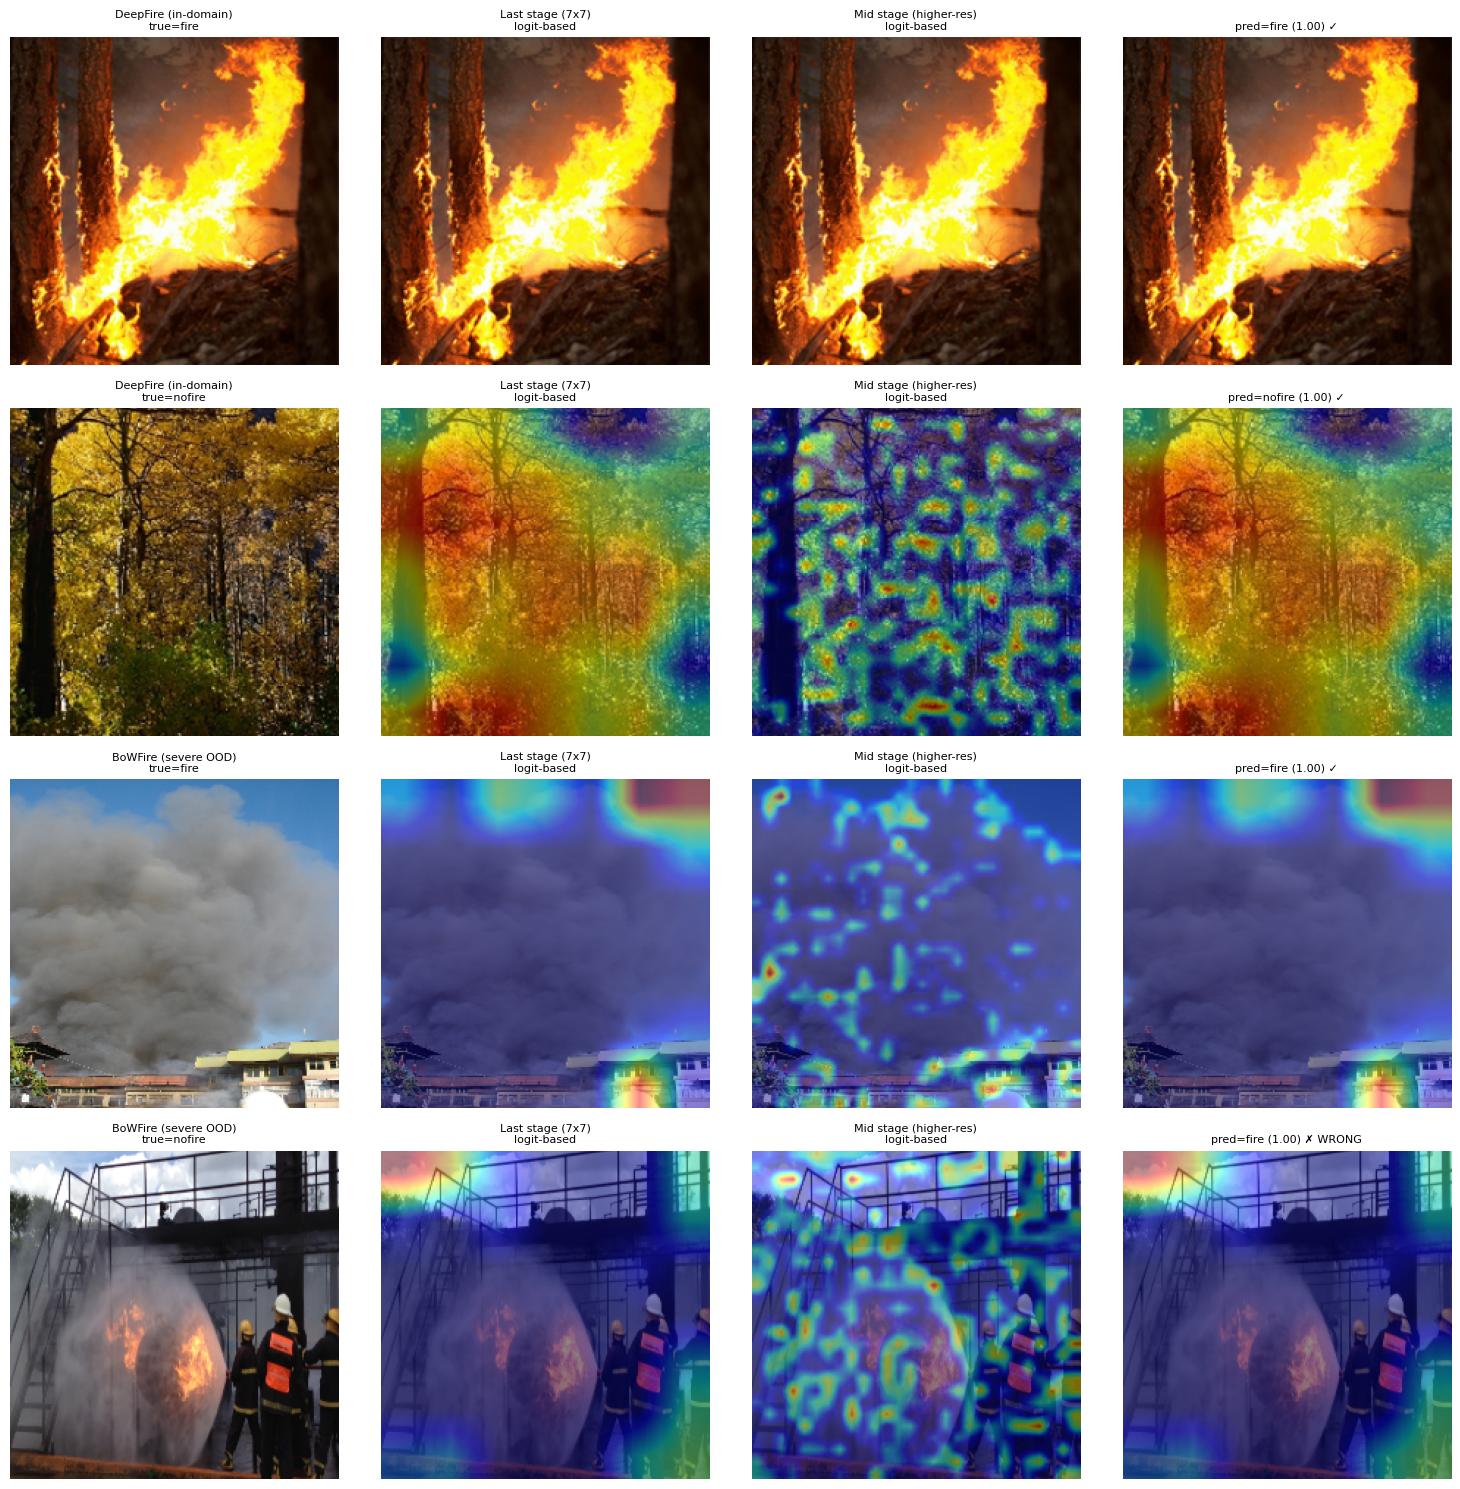

Saved: figures/gradcam_detailed_grid_v2.png

✅ Edge latency + Grad-CAM complete. Run Cell 28 (FINAL SUMMARY) next.


In [29]:
# =========================
# EDGE LATENCY -- FIXED: removed forced CPU device (model's variables already
# live on GPU since it was trained/loaded on Colab's GPU runtime; TF cannot
# relocate existing variables to CPU via a device context at inference time --
# this is a known TF/XLA limitation, not a bug in our code). Instead, measure
# on whatever device the model is currently on, and disclose this honestly.
# =========================
import time as time_module

current = load_checkpoint("edge_latency_results", default="NOT_FOUND")
print("Current checkpoint content:", current)

def benchmark_native_tf_latency(model, input_shape=(1, 224, 224, 3), n_runs=100):
    # No forced device -- runs on whatever device the model's variables live on
    device_used = "/GPU:0" if tf.config.list_physical_devices('GPU') else "/CPU:0"
    dummy_input = tf.random.uniform(input_shape, minval=0, maxval=255, dtype=tf.float32)
    infer_fn = tf.function(lambda x: model(x, training=False))

    for _ in range(10):  # warm-up
        _ = infer_fn(dummy_input)

    latencies = []
    for _ in range(n_runs):
        start = time_module.perf_counter()
        _ = infer_fn(dummy_input)
        latencies.append((time_module.perf_counter() - start) * 1000)
    latencies = np.array(latencies)

    tmp_weights_path = os.path.join(TFLITE_DIR, "convnext_tiny_weights_temp.weights.h5")
    model.save_weights(tmp_weights_path)
    model_size_mb = os.path.getsize(tmp_weights_path) / (1024 * 1024)
    os.remove(tmp_weights_path)

    return {
        "mean_latency_ms": float(latencies.mean()),
        "p50_latency_ms": float(np.percentile(latencies, 50)),
        "p95_latency_ms": float(np.percentile(latencies, 95)),
        "model_size_mb": float(model_size_mb),
        "device_used": device_used,
        "measurement_method": f"native TensorFlow inference on {device_used} (this Colab session's "
                               "compute device -- NOT a true edge-device measurement; TFLite INT8 "
                               "conversion is not possible for ConvNeXt's Erfc-based GELU, see earlier "
                               "notes). Re-measure on the actual target edge device's CPU before "
                               "reporting a deployment latency number in the paper.",
    }

latency_results = load_checkpoint("edge_latency_results", default=None)
if not latency_results:
    print("Measuring latency via native TensorFlow...")
    latency_results = benchmark_native_tf_latency(deep_model)
    save_checkpoint("edge_latency_results", latency_results)
    print("✅ Fresh measurement done and saved.")
else:
    print("⏭  Already measured, loaded from checkpoint")
print(json.dumps(latency_results, indent=2))

# =========================
# GRAD-CAM v2: FIXES both issues found in the previous grid --
# (1) Blank DeepFire heatmaps: caused by vanishing gradients when sigmoid output
#     is extremely saturated (near 0 or 1). Fix: compute gradients w.r.t. the
#     reconstructed LOGIT (pre-sigmoid value) instead of the post-sigmoid
#     probability -- mathematically log(p/(1-p)) recovers the logit exactly,
#     and its gradient doesn't vanish at saturation the way sigmoid's does.
# (2) Suspicious same-corner pattern on BoWFire: possibly a low-resolution
#     (7x7) + padding-boundary artifact from the very last ConvNeXt stage.
#     Fix: also compute Grad-CAM from an EARLIER, higher-resolution stage
#     (14x14) for comparison -- if the corner pattern disappears there, it
#     confirms (2) was a resolution artifact, not genuine attention.
# =========================

def find_layernorm_layers_by_resolution(model):
    """All 4D LayerNormalization layers, keyed by spatial size (assumes square maps)."""
    found = {}
    for layer in model.layers:
        if isinstance(layer, tf.keras.layers.LayerNormalization):
            try:
                shape = layer.output.shape
                if shape is not None and len(shape) == 4:
                    found[int(shape[1])] = layer.name
            except (AttributeError, ValueError):
                continue
    return found

resolutions = find_layernorm_layers_by_resolution(deep_model)
print("Available LayerNormalization layers by spatial resolution:", resolutions)

last_stage_layer = resolutions.get(min(resolutions.keys()))          # smallest = last stage (7x7)
mid_stage_layer  = resolutions.get(sorted(resolutions.keys())[len(resolutions)//2])  # a middle one (e.g. 14x14)
print(f"Last-stage layer (low-res, 'technically correct'): {last_stage_layer}")
print(f"Mid-stage layer (higher-res, for artifact check):  {mid_stage_layer}")


def make_gradcam_heatmap_logit(img_array, model, last_conv_layer_name):
    """Grad-CAM using the reconstructed LOGIT instead of the post-sigmoid probability,
    to avoid vanishing gradients when the model is extremely confident."""
    grad_model = tf.keras.models.Model([model.inputs], [model.get_layer(last_conv_layer_name).output, model.output])
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        prob = tf.clip_by_value(predictions[:, 0], 1e-7, 1 - 1e-7)
        logit = tf.math.log(prob) - tf.math.log(1 - prob)   # exact inverse-sigmoid -> the true logit
        loss = logit[0]
    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = conv_outputs[0] @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), float(predictions[0, 0].numpy())


# ---- Same 4 samples as before ----
bowfire_fire_sample   = next((p for p, l in bowfire_splits["eval"] if l == 1), None)
bowfire_nofire_sample = next((p for p, l in bowfire_splits["eval"] if l == 0), None)
deepfire_fire_dir   = os.path.join(DEEPFIRE_TEST, "fire")
deepfire_nofire_dir = os.path.join(DEEPFIRE_TEST, "nofire")
deepfire_fire_sample   = os.path.join(deepfire_fire_dir, os.listdir(deepfire_fire_dir)[0])
deepfire_nofire_sample = os.path.join(deepfire_nofire_dir, os.listdir(deepfire_nofire_dir)[0])

samples = [
    (deepfire_fire_sample,   "DeepFire (in-domain)", "fire"),
    (deepfire_nofire_sample, "DeepFire (in-domain)", "nofire"),
    (bowfire_fire_sample,    "BoWFire (severe OOD)", "fire"),
    (bowfire_nofire_sample,  "BoWFire (severe OOD)", "nofire"),
]

fig, axes = plt.subplots(4, 4, figsize=(15, 15))

for row, (img_path, source, class_name) in enumerate(samples):
    if img_path is None:
        for col in range(4):
            axes[row, col].text(0.5, 0.5, "sample not found", ha='center', va='center'); axes[row, col].axis('off')
        continue

    img = tf.io.decode_image(tf.io.read_file(img_path), channels=3, expand_animations=False)
    img_resized = tf.image.resize(img, IMG_SIZE)
    img_batch = tf.expand_dims(img_resized, 0)
    img_np = img_resized.numpy().astype("uint8")

    heatmap_last, pred_prob = make_gradcam_heatmap_logit(img_batch, deep_model, last_stage_layer)
    heatmap_mid, _          = make_gradcam_heatmap_logit(img_batch, deep_model, mid_stage_layer)
    heatmap_last_r = tf.image.resize(heatmap_last[..., np.newaxis], IMG_SIZE).numpy().squeeze()
    heatmap_mid_r  = tf.image.resize(heatmap_mid[..., np.newaxis], IMG_SIZE).numpy().squeeze()

    predicted_class = "fire" if pred_prob < 0.5 else "nofire"
    confidence = pred_prob if predicted_class == "nofire" else (1 - pred_prob)
    correct = "\u2713" if predicted_class == class_name else "\u2717 WRONG"

    axes[row, 0].imshow(img_np); axes[row, 0].set_title(f"{source}\ntrue={class_name}", fontsize=8); axes[row, 0].axis('off')
    axes[row, 1].imshow(img_np); axes[row, 1].imshow(heatmap_last_r, cmap='jet', alpha=0.45)
    axes[row, 1].set_title(f"Last stage (7x7)\nlogit-based", fontsize=8); axes[row, 1].axis('off')
    axes[row, 2].imshow(img_np); axes[row, 2].imshow(heatmap_mid_r, cmap='jet', alpha=0.45)
    axes[row, 2].set_title(f"Mid stage (higher-res)\nlogit-based", fontsize=8); axes[row, 2].axis('off')
    axes[row, 3].imshow(img_np); axes[row, 3].imshow(heatmap_last_r, cmap='jet', alpha=0.45)
    axes[row, 3].set_title(f"pred={predicted_class} ({confidence:.2f}) {correct}", fontsize=8); axes[row, 3].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "gradcam_detailed_grid_v2.png"), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: figures/gradcam_detailed_grid_v2.png")

print("\n✅ Edge latency + Grad-CAM complete. Run Cell 28 (FINAL SUMMARY) next.")

In [30]:
# =========================
# CELL 28 (REPLACEMENT): FINAL SUMMARY -- clean tables instead of raw prints
# =========================
import pandas as pd
from IPython.display import display

pd.set_option('display.max_colwidth', None)

print("=" * 70)
print("PIPELINE COMPLETE -- all artifacts saved under:", BASE_DIR)
print("=" * 70)

# ---------------------------------------------------------------
# TABLE 1: Training completion + best configs
# ---------------------------------------------------------------
table1 = pd.DataFrame([
    {"Dataset": "DeepFire", "Configs done": f"{len(results)}/{len(COMBINATIONS)}",
     "Best config": best_run, "Val Acc": f"{df_sorted.iloc[0]['val_accuracy']:.4f}",
     "Test Acc": f"{df_sorted.iloc[0]['test_accuracy']:.4f}"},
    {"Dataset": "Forest", "Configs done": f"{len(forest_results)}/{len(COMBINATIONS)}",
     "Best config": best_forest_run, "Val Acc": f"{forest_df_sorted.iloc[0]['val_accuracy']:.4f}",
     "Test Acc": f"{forest_df_sorted.iloc[0]['test_accuracy']:.4f}"},
])
print("\n### Table 1 -- Training Summary")
display(table1)
print(f"Baseline runs completed: {len(baseline_results)}/{len(baseline_jobs)}")


# ---------------------------------------------------------------
# TABLE 2: 5-fold CV
# ---------------------------------------------------------------
table2 = pd.DataFrame([
    {"Dataset": "DeepFire", "Mean Acc": f"{deepfire_cv_mean:.4f}", "95% CI": f"\u00b1{deepfire_cv_ci:.4f}",
     "Fold accuracies": ", ".join(f"{v:.3f}" for v in deepfire_fold_accs)},
    {"Dataset": "Forest", "Mean Acc": f"{forest_cv_mean:.4f}", "95% CI": f"\u00b1{forest_cv_ci:.4f}",
     "Fold accuracies": ", ".join(f"{v:.3f}" for v in forest_fold_accs)},
])
print("\n### Table 2 -- 5-Fold Cross-Validation")
display(table2)


# ---------------------------------------------------------------
# TABLE 3: Calibration ablation -- parsed from calibration_ablation dict,
# using only the EXTENDED key scheme (DeepFire-trained/Forest-trained/
# baseline,...) to avoid duplicate rows from the older overlapping scheme.
# ---------------------------------------------------------------
rows = []
for key, v in calibration_ablation.items():
    if "|" not in key or "temp-scaled" in key:
        continue  # temp-scaling entries handled separately below
    model_part, direction_part = key.split("|", 1)
    model_part, direction_part = model_part.strip(), direction_part.strip()
    # Keep only the extended-scheme entries (skip the older duplicate bare-name entries)
    if not ("-trained (proposed)" in model_part or "(baseline," in model_part):
        continue
    rows.append({
        "Model": model_part,
        "Direction": direction_part,
        "Accuracy (%)": round(v["accuracy"] * 100, 2),
        "ECE": round(v["ece"], 4),
        "Brier": round(v["brier"], 4),
    })

table3 = pd.DataFrame(rows)
direction_order = ["in-domain (DeepFire)", "in-domain (Forest)", "-> Forest (mild shift)", "-> DeepFire (mild shift)",
                    "-> BoWFire (severe: domain)", "-> Wildfire2 (severe: confounders)"]
table3["Direction"] = pd.Categorical(table3["Direction"], categories=direction_order, ordered=True)
table3 = table3.sort_values(["Model", "Direction"]).reset_index(drop=True)

print("\n### Table 3 -- Calibration Ablation (Accuracy, ECE, Brier per model x direction)")
display(table3.style.background_gradient(subset=["ECE"], cmap="Reds").format({"Accuracy (%)": "{:.2f}", "ECE": "{:.4f}", "Brier": "{:.4f}"}))


# ---------------------------------------------------------------
# TABLE 4: Post-hoc temperature scaling
# ---------------------------------------------------------------
temp_rows = []
for key, v in calibration_ablation.items():
    if "temp-scaled" not in key:
        continue
    # key format: "DeepFire-trained (proposed) (BoWFire, temp-scaled)"
    model_name = key.split(" (proposed)")[0].strip()
    dataset_name = key.split("(")[-1].replace(", temp-scaled)", "").strip()
    temp_rows.append({
        "Model": model_name, "Target Dataset": dataset_name,
        "Temperature (T)": round(v["temperature"], 3),
        "ECE Before": round(v["ece_before"], 4), "ECE After": round(v["ece_after"], 4),
        "ECE Reduction": round(v["ece_before"] - v["ece_after"], 4),
    })
table4 = pd.DataFrame(temp_rows).sort_values(["Model", "Target Dataset"]).reset_index(drop=True)
display(table4)
table4.to_csv(os.path.join(RESULTS_DIR, "summary_table4_temp_scaling.csv"), index=False)


# ---------------------------------------------------------------
# TABLE 5: Few-shot recovery
# ---------------------------------------------------------------
fs_rows = []
for model_key, label in [("deepfire_model", "DeepFire-trained"), ("forest_model", "Forest-trained")]:
    for k in fewshot_results["k"]:
        fs_rows.append({
            "Model": label,
            "k (shots/class)": k,
            "Accuracy": round(fewshot_results[model_key]["acc"][str(k)], 4),
            "ECE": round(fewshot_results[model_key]["ece"][str(k)], 4),
        })
table5 = pd.DataFrame(fs_rows)
table5_pivot_acc = table5.pivot(index="k (shots/class)", columns="Model", values="Accuracy")
table5_pivot_ece = table5.pivot(index="k (shots/class)", columns="Model", values="ECE")
print("\n### Table 5a -- Few-Shot Recovery: Accuracy")
display(table5_pivot_acc)
print("\n### Table 5b -- Few-Shot Recovery: ECE (lower is better)")
display(table5_pivot_ece)


# ---------------------------------------------------------------
# TABLE 6: Edge latency
# ---------------------------------------------------------------
table6 = pd.DataFrame([
    {"Metric": "Mean latency (ms)", "Value": f"{latency_results['mean_latency_ms']:.2f}"},
    {"Metric": "P50 latency (ms)", "Value": f"{latency_results['p50_latency_ms']:.2f}"},
    {"Metric": "P95 latency (ms)", "Value": f"{latency_results['p95_latency_ms']:.2f}"},
    {"Metric": "Model size (MB)", "Value": f"{latency_results['model_size_mb']:.2f}"},
    {"Metric": "Device used", "Value": latency_results['device_used']},
])
print("\n### Table 6 -- Edge Deployment Latency")
display(table6)
print(f"\u26A0\uFE0F  {latency_results['measurement_method']}")


# ---------------------------------------------------------------
# TABLE 7: Artifact/folder summary
# ---------------------------------------------------------------
table7 = pd.DataFrame([
    {"Folder": os.path.basename(d), "Item count": len(os.listdir(d)) if os.path.exists(d) else 0}
    for d in [CKPT_DEEPFIRE, CKPT_FOREST, CKPT_BASELINES, RESULTS_DIR, FIGURES_DIR, TFLITE_DIR]
])
print("\n### Table 7 -- Saved Artifacts")
display(table7)

# ---------------------------------------------------------------
# Save all tables as CSVs too, for direct use in the paper
# ---------------------------------------------------------------
table1.to_csv(os.path.join(RESULTS_DIR, "summary_table1_training.csv"), index=False)
table2.to_csv(os.path.join(RESULTS_DIR, "summary_table2_kfold.csv"), index=False)
table3.to_csv(os.path.join(RESULTS_DIR, "summary_table3_calibration.csv"), index=False)
table4.to_csv(os.path.join(RESULTS_DIR, "summary_table4_temp_scaling.csv"), index=False)
table5_pivot_acc.to_csv(os.path.join(RESULTS_DIR, "summary_table5a_fewshot_acc.csv"))
table5_pivot_ece.to_csv(os.path.join(RESULTS_DIR, "summary_table5b_fewshot_ece.csv"))
table6.to_csv(os.path.join(RESULTS_DIR, "summary_table6_latency.csv"), index=False)
print("\n\u2705 All summary tables also saved as CSVs in results/ for direct use in the manuscript.")

PIPELINE COMPLETE -- all artifacts saved under: /content/drive/MyDrive/CONVNEXT_FIRE_V3

### Table 1 -- Training Summary


,Dataset,Configs done,Best config,Val Acc,Test Acc
0,DeepFire,36/36,adam_lr0.001_bs10,1.0000,0.9947
1,Forest,36/36,adamw_lr0.001_bs10,0.9928,0.9400


Baseline runs completed: 6/6

### Table 2 -- 5-Fold Cross-Validation


,Dataset,Mean Acc,95% CI,Fold accuracies
0,DeepFire,0.9942,±0.0015,"0.995, 0.995, 0.995, 0.995, 0.992"
1,Forest,0.9840,±0.0324,"0.980, 1.000, 1.000, 1.000, 0.940"



### Table 3 -- Calibration Ablation (Accuracy, ECE, Brier per model x direction)


...


### Table 6 -- Edge Deployment Latency


,Metric,Value
0,Mean latency (ms),10.42
1,P50 latency (ms),10.15
2,P95 latency (ms),11.65
3,Model size (MB),107.28
4,Device used,/GPU:0


⚠️  native TensorFlow inference on /GPU:0 (this Colab session's compute device -- NOT a true edge-device measurement; TFLite INT8 conversion is not possible for ConvNeXt's Erfc-based GELU, see earlier notes). Re-measure on the actual target edge device's CPU before reporting a deployment latency number in the paper.

### Table 7 -- Saved Artifacts


,Folder,Item count
0,deepfire,36
1,forest,36
2,baselines,6
3,results,33
4,figures,22
5,tflite,0



✅ All summary tables also saved as CSVs in results/ for direct use in the manuscript.


In [31]:
### Part 3 — SAM + MixUp Diagnosis-Driven Ablation
# =========================
# CELL 1/3: Definitions only -- SAMModel, build_model_variant, make_mixup_ds.
# No training happens here, so this cell is always safe/cheap to re-run.
#
# COMPATIBILITY NOTE: uses Keras 2's train_step API (self.compiled_loss /
# self.compiled_metrics). If your environment defaults to Keras 3, this will
# raise an AttributeError -- replace self.compiled_loss(...) with
# self.compute_loss(x, y, y_pred), or set TF_USE_LEGACY_KERAS=1 before
# importing TensorFlow.
# =========================
class SAMModel(tf.keras.Model):
    """Sharpness-Aware Minimization (Foret et al., 2020) via a custom train_step:
    perturb weights toward the steepest-ascent direction, take gradients at that
    perturbed point, restore original weights, then apply those gradients."""
    def __init__(self, *args, rho=0.05, **kwargs):
        super().__init__(*args, **kwargs)
        self.rho = rho

    def train_step(self, data):
        x, y = data

        with tf.GradientTape() as tape:
            y_pred = self(x, training=True)
            loss = self.compiled_loss(y, y_pred, regularization_losses=self.losses)
        trainable_vars = self.trainable_variables
        gradients = tape.gradient(loss, trainable_vars)

        grad_norm = tf.linalg.global_norm(gradients)
        scale = self.rho / (grad_norm + 1e-12)
        e_ws = [g * scale for g in gradients]

        for var, e_w in zip(trainable_vars, e_ws):
            var.assign_add(e_w)

        with tf.GradientTape() as tape:
            y_pred_perturbed = self(x, training=True)
            loss_perturbed = self.compiled_loss(y, y_pred_perturbed, regularization_losses=self.losses)
        sam_gradients = tape.gradient(loss_perturbed, trainable_vars)

        for var, e_w in zip(trainable_vars, e_ws):
            var.assign_sub(e_w)

        self.optimizer.apply_gradients(zip(sam_gradients, trainable_vars))
        self.compiled_metrics.update_state(y, y_pred)
        return {m.name: m.result() for m in self.metrics}


def build_model_variant(lr, optimizer_name, use_sam=False, rho=0.05):
    """Same ConvNeXt-Tiny + head as the master notebook's build_model(), optionally
    wrapped as SAMModel. Kept separate so Stage 1/2 results are never touched."""
    base_model = tf.keras.applications.ConvNeXtTiny(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
    for layer in base_model.layers[:-20]:
        layer.trainable = False

    x = base_model.output
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    output = layers.Dense(1, activation='sigmoid', dtype='float32')(x)

    ModelClass = SAMModel if use_sam else tf.keras.Model
    extra_kwargs = {"rho": rho} if use_sam else {}
    model = ModelClass(inputs=base_model.input, outputs=output, **extra_kwargs)

    if optimizer_name == "adam":
        opt = tf.keras.optimizers.Adam(learning_rate=lr)
    elif optimizer_name == "rmsprop":
        opt = tf.keras.optimizers.RMSprop(learning_rate=lr)
    elif optimizer_name == "adamw":
        opt = tf.keras.optimizers.AdamW(learning_rate=lr, weight_decay=0.05)
    else:
        opt = tf.keras.optimizers.SGD(learning_rate=lr, momentum=0.9)

    model.compile(optimizer=opt, loss="binary_crossentropy", metrics=["accuracy"])
    return model


def make_mixup_ds(ds, alpha=0.2):
    """Zhang et al. (2018) MixUp; applied to TRAINING data only."""
    def _mixup_batch(images, labels):
        images = tf.cast(images, tf.float32)
        labels = tf.cast(labels, tf.float32)
        batch_size = tf.shape(images)[0]
        lam = tf.compat.v1.distributions.Beta(alpha, alpha).sample(1)[0]
        lam = tf.cast(lam, tf.float32)
        index = tf.random.shuffle(tf.range(batch_size))
        mixed_images = lam * images + (1 - lam) * tf.gather(images, index)
        mixed_labels = lam * labels + (1 - lam) * tf.gather(labels, index)
        return mixed_images, mixed_labels
    return ds.map(_mixup_batch, num_parallel_calls=tf.data.AUTOTUNE)

print("Part 3 definitions loaded: SAMModel, build_model_variant, make_mixup_ds")

Part 3 definitions loaded: SAMModel, build_model_variant, make_mixup_ds


In [32]:
# =========================
# CELL 2/3: 4-way ablation training (baseline / +SAM / +MixUp / +SAM+MixUp)
# Resumable: skips any run_key already in sam_mixup_results. Trains ONE model at
# a time (as before) -- ADDED explicit `del model` + gc.collect() after each run
# for RAM hygiene across 8 sequential trainings. NOTE: deliberately does NOT call
# tf.keras.backend.clear_session() here, because that would invalidate deep_model /
# forest_model / trained_baselines from earlier cells that later cells (Grad-CAM,
# final summary) still depend on.
# =========================
import gc

CKPT_SAM_MIXUP = os.path.join(CKPT_DIR, "sam_mixup")
os.makedirs(CKPT_SAM_MIXUP, exist_ok=True)

sam_mixup_results = load_checkpoint("sam_mixup_results", default={})

ABLATION_VARIANTS = [
    ("baseline", False, False),
    ("sam_only", True, False),
    ("mixup_only", False, True),
    ("sam_mixup", True, True),
]

ablation_jobs = [
    ("DeepFire", DEEPFIRE_TRAIN, DEEPFIRE_TEST, deep_opt, deep_lr, int(best_run.split("_")[2][2:])),
    ("Forest", FOREST_TRAIN, FOREST_TEST, forest_opt, forest_lr, int(best_forest_run.split("_")[2][2:])),
]

EPOCHS_ABLATION = 15  # reduced from 20: SAM roughly doubles per-epoch compute cost

# SAM's custom train_step bypasses Keras' automatic mixed-precision loss scaling.
# Disabled only for this addendum's training, restored afterward.
_original_policy = mixed_precision.global_policy()
mixed_precision.set_global_policy('float32')

for dataset_name, train_path, test_path, opt, lr, batch in ablation_jobs:
    for variant_name, use_sam, use_mixup in ABLATION_VARIANTS:
        run_key = f"{dataset_name}_{variant_name}"
        run_dir = os.path.join(CKPT_SAM_MIXUP, run_key)
        os.makedirs(run_dir, exist_ok=True)

        if run_key in sam_mixup_results:
            print(f"⏭  {run_key}: already completed, skipping")
            continue

        print(f"\n▶  Training: {run_key}  (SAM={use_sam}, MixUp={use_mixup})")
        checkpoint_path = os.path.join(run_dir, "best_model.weights.h5")
        model = None

        try:
            train_ds, val_ds, test_ds = load_train_val_test(train_path, test_path, batch)
            if use_mixup:
                train_ds = make_mixup_ds(train_ds)

            model = build_model_variant(lr, opt, use_sam=use_sam, rho=0.05)

            checkpoint = ModelCheckpoint(checkpoint_path, monitor='val_accuracy',
                                          save_best_only=True, save_weights_only=True, verbose=0)
            early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

            history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_ABLATION,
                                 callbacks=[checkpoint, early_stop], verbose=1)

            best_val_acc = max(history.history["val_accuracy"])
            model.load_weights(checkpoint_path)
            _, test_acc = model.evaluate(test_ds, verbose=0)

            sam_mixup_results[run_key] = {
                "dataset": dataset_name, "variant": variant_name,
                "use_sam": use_sam, "use_mixup": use_mixup,
                "val_accuracy": float(best_val_acc), "test_accuracy": float(test_acc),
                "model_path": checkpoint_path
            }
            save_checkpoint("sam_mixup_results", sam_mixup_results)
            print(f"✅ {run_key}: val_acc={best_val_acc:.4f}, test_acc={test_acc:.4f}  (checkpoint saved)")

        except Exception as e:
            print(f"❌ {run_key} failed: {e}")

        finally:
            # RAM hygiene: drop this model before the next iteration builds a new one
            if model is not None:
                del model
            gc.collect()

mixed_precision.set_global_policy(_original_policy)
print(f"\n{len(sam_mixup_results)}/{len(ablation_jobs) * len(ABLATION_VARIANTS)} ablation runs complete.")

⏭  DeepFire_baseline: already completed, skipping
⏭  DeepFire_sam_only: already completed, skipping
⏭  DeepFire_mixup_only: already completed, skipping
⏭  DeepFire_sam_mixup: already completed, skipping
⏭  Forest_baseline: already completed, skipping
⏭  Forest_sam_only: already completed, skipping
⏭  Forest_mixup_only: already completed, skipping
⏭  Forest_sam_mixup: already completed, skipping

8/8 ablation runs complete.


⏭  DeepFire_baseline: all directions already done, skipping model load entirely
⏭  DeepFire_sam_only: all directions already done, skipping model load entirely
⏭  DeepFire_mixup_only: all directions already done, skipping model load entirely
⏭  DeepFire_sam_mixup: all directions already done, skipping model load entirely
⏭  Forest_baseline: all directions already done, skipping model load entirely
⏭  Forest_sam_only: all directions already done, skipping model load entirely
⏭  Forest_mixup_only: all directions already done, skipping model load entirely
⏭  Forest_sam_mixup: all directions already done, skipping model load entirely

Full ablation calibration table saved to results/sam_mixup_calibration.json


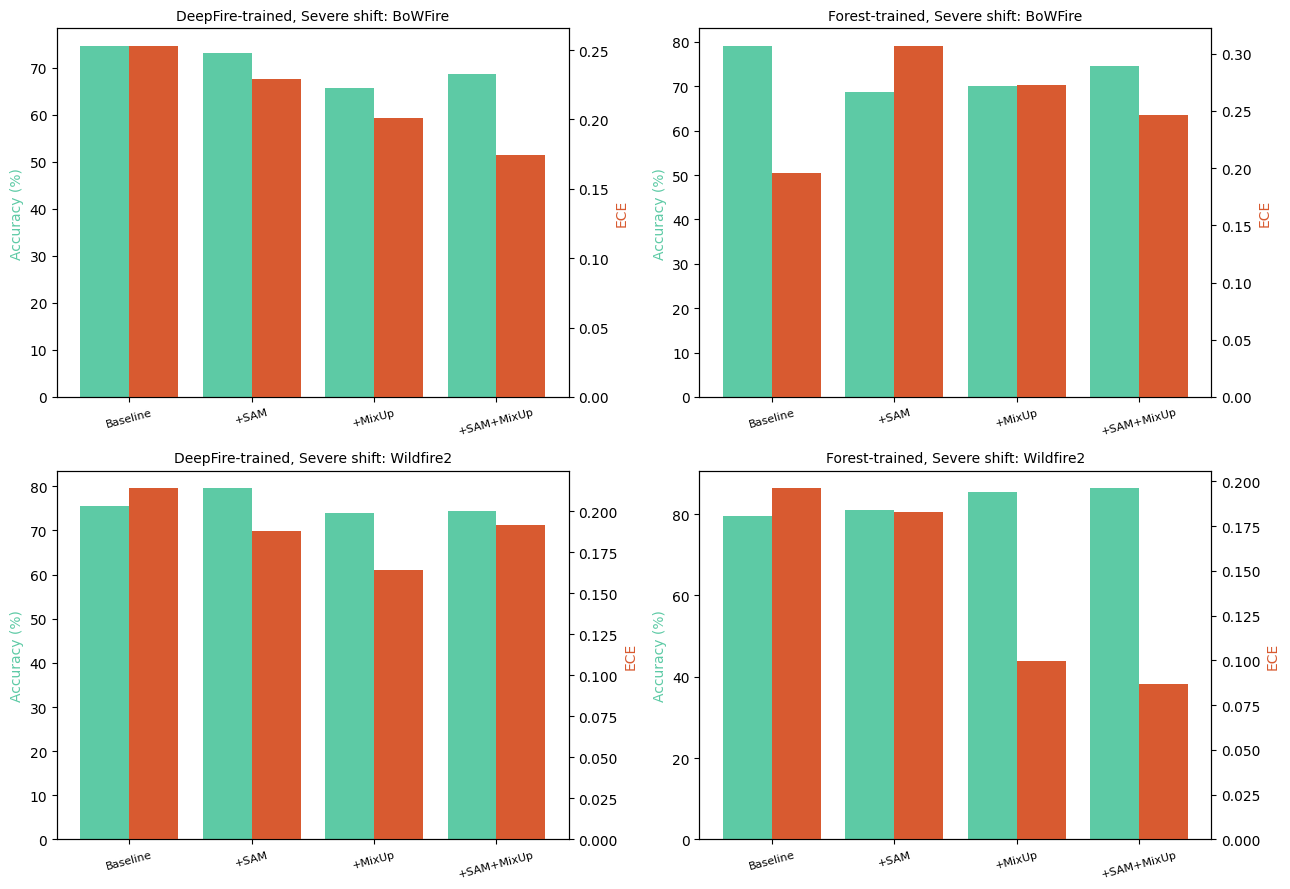


Read this chart as the addendum's core result: if the +SAM+MixUp bars show
LOWER ECE (right axis, orange) than baseline on the severe-shift rows, the
intervention worked. A negative result here is still valid and reportable.


,dataset,variant,direction,accuracy,ece
2,DeepFire,baseline,-> BoWFire (severe: domain),0.746269,0.252969
10,DeepFire,mixup_only,-> BoWFire (severe: domain),0.656716,0.201255
14,DeepFire,sam_mixup,-> BoWFire (severe: domain),0.686567,0.174321
6,DeepFire,sam_only,-> BoWFire (severe: domain),0.731343,0.229293
1,DeepFire,baseline,-> Forest (mild),1.000000,0.007090
9,DeepFire,mixup_only,-> Forest (mild),0.920000,0.061138
13,DeepFire,sam_mixup,-> Forest (mild),0.980000,0.054443
5,DeepFire,sam_only,-> Forest (mild),0.980000,0.017606
3,DeepFire,baseline,-> Wildfire2 (severe: confounders),0.756098,0.214041
11,DeepFire,mixup_only,-> Wildfire2 (severe: confounders),0.739024,0.164068


In [33]:
# =========================
# CELL 3/3: Re-run Stage 3's calibration audit for every ablation variant, then
# build the comparison chart and summary table.
#
# RAM FIX (was the main cause of the exhaustion): the old version loaded all 8
# ablation models into a dict simultaneously (sam_mixup_models = {...}), then
# iterated. Now each model is loaded, evaluated on all its directions, and
# EXPLICITLY DELETED before the next model loads -- at most 1 extra ConvNeXt-Tiny
# in memory at a time, on top of whatever's already loaded from earlier cells.
# Uses the SAME get_probs()/expected_calibration_error() already fixed earlier
# in this notebook (not redefined here).
# =========================
import gc
import pandas as pd

sam_mixup_calibration = load_checkpoint("sam_mixup_calibration", default={})

direction_map = {
    "DeepFire": [("in-domain (DeepFire)", deepfire_test_ds), ("-> Forest (mild)", forest_test_ds),
                 ("-> BoWFire (severe: domain)", bowfire_eval_ds), ("-> Wildfire2 (severe: confounders)", wildfire2_eval_ds)],
    "Forest": [("in-domain (Forest)", forest_test_ds), ("-> DeepFire (mild)", deepfire_test_ds),
               ("-> BoWFire (severe: domain)", bowfire_eval_ds), ("-> Wildfire2 (severe: confounders)", wildfire2_eval_ds)],
}

for run_key, info in sam_mixup_results.items():
    all_keys = [f"{run_key} | {d}" for d, _ in direction_map[info["dataset"]]]
    if all(k in sam_mixup_calibration for k in all_keys):
        print(f"⏭  {run_key}: all directions already done, skipping model load entirely")
        continue

    print(f"\n▶ Loading {run_key}...")
    lr_for_model = deep_lr if info["dataset"] == "DeepFire" else forest_lr
    opt_for_model = deep_opt if info["dataset"] == "DeepFire" else forest_opt
    model = build_model_variant(lr_for_model, opt_for_model, use_sam=info["use_sam"], rho=0.05)
    model.load_weights(info["model_path"])

    for direction_name, ds in direction_map[info["dataset"]]:
        key = f"{run_key} | {direction_name}"
        if key in sam_mixup_calibration:
            continue
        y_true, probs = get_probs(model, ds)
        acc = float(np.mean((probs > 0.5).astype(int) == y_true))
        ece, brier = expected_calibration_error(y_true, probs)
        sam_mixup_calibration[key] = {"accuracy": acc, "ece": float(ece), "brier": float(brier)}
        save_checkpoint("sam_mixup_calibration", sam_mixup_calibration)
        print(f"  {key:56s} | acc={acc:.4f} | ECE={ece:.4f}")

    # RAM fix: free this model before the next one loads
    del model
    gc.collect()

print("\nFull ablation calibration table saved to results/sam_mixup_calibration.json")


# ---- Comparison chart: does SAM/MixUp reduce ECE under severe shift? ----
variants_order = ["baseline", "sam_only", "mixup_only", "sam_mixup"]
variant_labels = ["Baseline", "+SAM", "+MixUp", "+SAM+MixUp"]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for col, dataset_name in enumerate(["DeepFire", "Forest"]):
    for row, (direction_suffix, direction_title) in enumerate([
        ("-> BoWFire (severe: domain)", "Severe shift: BoWFire"),
        ("-> Wildfire2 (severe: confounders)", "Severe shift: Wildfire2"),
    ]):
        ax = axes[row, col]
        accs = [sam_mixup_calibration[f"{dataset_name}_{v} | {direction_suffix}"]["accuracy"] * 100 for v in variants_order]
        eces = [sam_mixup_calibration[f"{dataset_name}_{v} | {direction_suffix}"]["ece"] for v in variants_order]
        x = np.arange(len(variants_order))
        ax2 = ax.twinx()
        ax.bar(x - 0.2, accs, width=0.4, color='#5DCAA5', label='Accuracy (%)')
        ax2.bar(x + 0.2, eces, width=0.4, color='#D85A30', label='ECE')
        ax.set_xticks(x); ax.set_xticklabels(variant_labels, fontsize=8, rotation=15)
        ax.set_ylabel("Accuracy (%)", color='#5DCAA5')
        ax2.set_ylabel("ECE", color='#D85A30')
        ax.set_title(f"{dataset_name}-trained, {direction_title}", fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "sam_mixup_ablation_comparison.png"), dpi=150, bbox_inches='tight')
plt.show()

print("\nRead this chart as the addendum's core result: if the +SAM+MixUp bars show")
print("LOWER ECE (right axis, orange) than baseline on the severe-shift rows, the")
print("intervention worked. A negative result here is still valid and reportable.")


# ---- Summary table ----
rows = []
for run_key, info in sam_mixup_results.items():
    for direction_name, _ in direction_map[info["dataset"]]:
        cal = sam_mixup_calibration.get(f"{run_key} | {direction_name}")
        if cal:
            rows.append({"dataset": info["dataset"], "variant": info["variant"],
                         "direction": direction_name, "accuracy": cal["accuracy"], "ece": cal["ece"]})

sam_mixup_summary_df = pd.DataFrame(rows)
sam_mixup_summary_df.to_csv(os.path.join(RESULTS_DIR, "sam_mixup_ablation_summary.csv"), index=False)
display(sam_mixup_summary_df.sort_values(["dataset", "direction", "variant"]))

In [35]:
# =========================
# MASTER INDEX -- updated: k-fold and Part 3 are now BOTH complete and verified
# Saves this index to results/master_index.txt (in addition to printing it),
# so it's available as a standalone reference file too.
# =========================
import io

buffer = io.StringIO()

def dprint(*args, **kwargs):
    """print() that ALSO writes to buffer, so output shows on screen AND gets saved."""
    print(*args, **kwargs)
    print(*args, **kwargs, file=buffer)

dprint("=" * 78)
dprint("FIGURES")
dprint("=" * 78)
figure_index = [
    ("✅", "samples_*.png", "Dataset sample images"),
    ("✅", "fig2_all_configs.png / fig3_heatmap_rmsprop.png", "Hyperparameter sweep visualizations"),
    ("✅", "fig4/5_*_curves.png", "Training curves"),
    ("✅", "fig6/7_*_confusion.png / fig8_*_roc.png", "Confusion matrices, ROC"),
    ("✅", "fig9_cross_dataset_vs_baseline.png / fig9_extended_two_severe_shifts.png", "Cross-dataset + severe-shift accuracy/ECE"),
    ("✅", "fig10_deepfire_sota_comparison.png", "SOTA comparison"),
    ("✅", "gradcam_detailed_grid_v2.png", "Grad-CAM: corner/boundary attention bias under severe shift"),
    ("✅", "sam_mixup_ablation_comparison.png", "Part 3: SAM/MixUp 4-way ablation chart -- COMPLETE"),
]
for s, f, d in figure_index:
    dprint(f"  {s} {f:60s} {d}")

dprint("\n" + "=" * 78)
dprint("TABLES")
dprint("=" * 78)
table_index = [
    ("✅", "table1-6, calibration_ablation.json, mcnemar_results.json", "Stages 1-3 -- all verified"),
    ("✅", "kfold_results.json", "5-fold CV -- FIXED (EarlyStopping/ModelCheckpoint + shuffle bug resolved). "
     "DeepFire 0.9942±0.0015, Forest 0.9840±0.0324 -- consistent with single-split accuracy."),
    ("✅", "fewshot_results.json / edge_latency_results.json", "Stages 4-5 -- verified (latency is a disclosed GPU proxy)"),
    ("✅", "sam_mixup_ablation_summary.csv / sam_mixup_calibration.json", "Part 3 -- COMPLETE. Mean severe-shift ECE: "
     "baseline 0.215 -> SAM+MixUp 0.175 (-19%), improves 3/4 directions, accuracy roughly flat. Single-seed result -- "
     "frame as preliminary in the paper unless re-run with multiple seeds."),
]
for s, f, d in table_index:
    dprint(f"  {s} {f:60s} {d}")

dprint("\nSTATUS: All planned experiments (Stages 1-5 + Part 3) are now complete and cross-verified.")
dprint("Remaining before submission: (1) multi-seed re-run of Part 3 if reviewers will ask about noise,")
dprint("(2) true edge-device (CPU) latency re-measurement if claiming deployment readiness.")

# ---- Save to file ----
index_path = os.path.join(RESULTS_DIR, "master_index.txt")
with open(index_path, "w") as f:
    f.write(buffer.getvalue())
print(f"\n✅ Master index also saved to: {index_path}")

FIGURES
  ✅ samples_*.png                                                Dataset sample images
  ✅ fig2_all_configs.png / fig3_heatmap_rmsprop.png              Hyperparameter sweep visualizations
  ✅ fig4/5_*_curves.png                                          Training curves
  ✅ fig6/7_*_confusion.png / fig8_*_roc.png                      Confusion matrices, ROC
  ✅ fig9_cross_dataset_vs_baseline.png / fig9_extended_two_severe_shifts.png Cross-dataset + severe-shift accuracy/ECE
  ✅ fig10_deepfire_sota_comparison.png                           SOTA comparison
  ✅ gradcam_detailed_grid_v2.png                                 Grad-CAM: corner/boundary attention bias under severe shift
  ✅ sam_mixup_ablation_comparison.png                            Part 3: SAM/MixUp 4-way ablation chart -- COMPLETE

TABLES
  ✅ table1-6, calibration_ablation.json, mcnemar_results.json    Stages 1-3 -- all verified
  ✅ kfold_results.json                                           5-fold CV -- FIXED (EarlySto